# 0.0 Imports

In [2]:
import builtins          as bt
import inflection
import lightgbm as lgb
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import seaborn as sns
import shap

from boruta                    import BorutaPy
from collections               import Counter
from IPython.display           import Image as image
from scipy                     import stats as ss
from sklearn                   import ensemble as en
from sklearn                   import metrics as mt
from sklearn                   import preprocessing as pp
from sklearn.feature_selection import VarianceThreshold, RFE, RFECV
from sklearn.ensemble          import RandomForestClassifier
from sklearn.linear_model      import LogisticRegression
from sklearn.metrics           import roc_auc_score, roc_curve, classification_report, confusion_matrix
from sklearn.model_selection   import train_test_split
from scipy                     import stats
from tabulate                  import tabulate
from typing                    import List, Dict
from xgboost                   import XGBClassifier

## 0.1 Helper Functions

In [3]:
# Função para colocar o ponto perto do próximo mínimo multiplo de bucket_size
def bucketize(point: float, bucket_size:float) -> float:
    return bucket_size * math.floor(point / bucket_size)

# Função para colocar os pontos em bukets e conta o número de pontos em cada bucket
def make_histogram(points: List[float], bucket_size: float) -> Dict[float, int]:
    return Counter([bucketize(point, bucket_size) for point in points])

def plot_histogram(points: List[float], bucket_size: float, title: str=""):
    histogram = make_histogram(points, bucket_size)
    plt.bar(histogram.keys(), histogram.values(), width=bucket_size)
    plt.title(title)

# Função métricas de avaliação de modelos
def ml_metrics(model_name, y_true, y_prob, threshold =0.5):
    y_pred = [ 1 if x > threshold else 0 for x in y_prob ]
    acc = mt.accuracy_score( y_true, y_pred )
    f1 = mt.f1_score( y_true, y_pred, zero_division=0 )
    prec = mt.precision_score( y_true, y_pred, zero_division=0 )
    rec = mt.recall_score(y_true, y_pred, zero_division=0)
    auc = mt.roc_auc_score(y_true, y_pred)

    return pd.DataFrame({
        'Model': model_name,
        'Accuracy': acc,
        'F1 Score': f1,
        'precision': prec,
        'Recall': rec,
        'AUC': auc
    }, index=[0])

## 0.2 Loading data

### 0.2.1 Data Train

In [4]:
df_raw = pd.read_csv('../dataset/train.csv')

In [5]:
df_raw.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [6]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service                   699635 non-null

### 0.2.2 Data Test

In [7]:
df_test = pd.read_csv('../dataset/test.csv')

# 1.0 DESCRICAO DOS DADOS

In [8]:
df1 = df_raw.copy()

In [9]:
df1.columns

Index(['id', 'Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender',
       'Customer Type', 'Type of Travel', 'Class', 'satisfaction'],
      dtype='str')

## 1.1 Rename columns

In [10]:

cols_old = [['id', 'Age', 'Flight Distance', 'Inflight wifi service',
             'Departure/Arrival time convenient', 'Ease of Online booking',
             'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 
             'Inflight entertainment', 'On-board service', 'Leg room service', 
             'Baggage handling', 'Checkin service', 'Cleanliness',
             'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender',
             'Customer Type', 'Type of Travel', 'Class', 'satisfaction']]

snakecase = lambda x: inflection.underscore( x.replace(" ", "_").replace("/", "_") )
cols_new = list(map(snakecase, cols_old[0]))

#rename
df1.columns = cols_new

In [11]:
cols_new

['id',
 'age',
 'flight_distance',
 'inflight_wifi_service',
 'departure_arrival_time_convenient',
 'ease_of_online_booking',
 'gate_location',
 'food_and_drink',
 'online_boarding',
 'seat_comfort',
 'inflight_entertainment',
 'on_board_service',
 'leg_room_service',
 'baggage_handling',
 'checkin_service',
 'cleanliness',
 'departure_delay_in_minutes',
 'arrival_delay_in_minutes',
 'gender',
 'customer_type',
 'type_of_travel',
 'class',
 'satisfaction']

## 1.2 Data Dimensions

In [12]:
print('Number of rows: {}'.format(df1.shape[0]))
print('Number of columns: {}'.format(df1.shape[1]))

Number of rows: 699635
Number of columns: 23


## 1.3 Data Types


In [13]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   age                                699635 non-null  int64  
 2   flight_distance                    699635 non-null  int64  
 3   inflight_wifi_service              699635 non-null  int64  
 4   departure_arrival_time_convenient  699635 non-null  int64  
 5   ease_of_online_booking             699635 non-null  int64  
 6   gate_location                      699635 non-null  int64  
 7   food_and_drink                     699635 non-null  int64  
 8   online_boarding                    699635 non-null  int64  
 9   seat_comfort                       699635 non-null  int64  
 10  inflight_entertainment             699635 non-null  int64  
 11  on_board_service                   699635 non-null

In [14]:
df1['satisfaction'].unique()


array([False,  True])

In [15]:
#TRANSFORMANDO BOLEANO EM NÚMERO INTEIRO
df1['satisfaction'] = df1['satisfaction'].astype(int)

In [16]:
pd.set_option("display.max_columns", None)
df1.head()

,id,age,flight_distance,inflight_wifi_service,departure_arrival_time_convenient,ease_of_online_booking,gate_location,food_and_drink,online_boarding,seat_comfort,inflight_entertainment,on_board_service,leg_room_service,baggage_handling,checkin_service,cleanliness,departure_delay_in_minutes,arrival_delay_in_minutes,gender,customer_type,type_of_travel,class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
1,1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,1
2,2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
3,3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,0
4,4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,0


In [17]:
df1.isna().sum()

id                                     0
age                                    0
flight_distance                        0
inflight_wifi_service                  0
departure_arrival_time_convenient      0
ease_of_online_booking                 0
gate_location                          0
food_and_drink                         0
online_boarding                        0
seat_comfort                           0
inflight_entertainment                 0
on_board_service                       0
leg_room_service                       0
baggage_handling                       0
checkin_service                        0
cleanliness                            0
departure_delay_in_minutes             0
arrival_delay_in_minutes             292
gender                                 0
customer_type                          0
type_of_travel                         0
class                                  0
satisfaction                           0
dtype: int64

## 1.5 Fillout NA

In [18]:
#logica de preenchimento de valores nulos, caso o valor de 'Arrival Delay in Minutes' seja nulo, ele será preenchido com o valor de 'Departure Delay in Minutes'
# os valores de Arrival Delay in Minutes e Departure Delay in Minutes são muito próximos e com alta correlação, 
# então preencher os valores nulos de Arrival Delay in Minutes com os valores de Departure Delay in Minutes pode ser uma boa estratégia para lidar com os valores nulos.
# outra estratégia boa seria apagar esses campos, mas perde dados. A média não é estratégia boa por conta do desbalanceamento dos dados, a mediana também não é boa por conta do desbalanceamento dos dados, e o valor mais frequente também não é boa estratégia por conta do desbalanceamento dos dados.
c = "arrival_delay_in_minutes"
d = "departure_delay_in_minutes"
df1[c] = df1[c].fillna(df1[d])


In [19]:
df1.isna().sum()

id                                   0
age                                  0
flight_distance                      0
inflight_wifi_service                0
departure_arrival_time_convenient    0
ease_of_online_booking               0
gate_location                        0
food_and_drink                       0
online_boarding                      0
seat_comfort                         0
inflight_entertainment               0
on_board_service                     0
leg_room_service                     0
baggage_handling                     0
checkin_service                      0
cleanliness                          0
departure_delay_in_minutes           0
arrival_delay_in_minutes             0
gender                               0
customer_type                        0
type_of_travel                       0
class                                0
satisfaction                         0
dtype: int64

## 1.7 Descriptive Statistical

In [20]:
num_attributes = df1.select_dtypes(include=['int64', 'float64']).drop(columns=['id'])
cat_attributes = df1.select_dtypes(exclude=['int64', 'float64'])

In [21]:
display(num_attributes)

,age,flight_distance,inflight_wifi_service,departure_arrival_time_convenient,ease_of_online_booking,gate_location,food_and_drink,online_boarding,seat_comfort,inflight_entertainment,on_board_service,leg_room_service,baggage_handling,checkin_service,cleanliness,departure_delay_in_minutes,arrival_delay_in_minutes,satisfaction
0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,0
1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,1
2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,0
3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,0
4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
699630,57,612,2,1,1,1,1,3,3,2,2,2,2,2,4,0,0.0,0
699631,30,862,2,2,2,3,4,2,4,4,2,5,4,2,4,24,34.0,0
699632,49,3148,5,5,5,5,4,4,4,5,5,5,5,5,5,0,0.0,1
699633,61,679,5,2,2,2,5,4,4,5,4,5,5,5,1,0,0.0,1


In [22]:
# Satisfação: 1 = satisfeitos, 0 = não satisfeitos
satisfaction_counts = df1['satisfaction'].value_counts()
print(f'Quantidade de passageiros satisfeitos: {satisfaction_counts[1]}')
print(f'Quantidade de passageiros insatisfeitos: {satisfaction_counts[0]}')

# Proporção de passageiros satisfeitos e insatisfeitos
satisfaction_proportion = df1['satisfaction'].value_counts(normalize=True)*100
print(f'Proporção de passageiros satisfeitos: {satisfaction_proportion[1]:.2f}%')
print(f'Proporção de passageiros insatisfeitos: {satisfaction_proportion[0]:.2f}%')

Quantidade de passageiros satisfeitos: 310339
Quantidade de passageiros insatisfeitos: 389296
Proporção de passageiros satisfeitos: 44.36%
Proporção de passageiros insatisfeitos: 55.64%


In [23]:
display(cat_attributes)

,gender,customer_type,type_of_travel,class
0,Female,Loyal Customer,Personal Travel,Eco
1,Male,Loyal Customer,Business travel,Business
2,Female,Loyal Customer,Personal Travel,Eco
3,Male,Loyal Customer,Personal Travel,Eco
4,Female,disloyal Customer,Business travel,Eco
...,...,...,...,...
699630,Female,Loyal Customer,Business travel,Eco
699631,Female,disloyal Customer,Business travel,Eco
699632,Male,Loyal Customer,Business travel,Business
699633,Female,Loyal Customer,Business travel,Eco


## 1.7.1 Numerical Attributes

In [24]:
#numerical statistics
#Central Tendency - mean, median
ct1 = pd.DataFrame(num_attributes.apply(np.mean)).T #média
ct2 = pd.DataFrame(num_attributes.apply(np.median)).T #mediana


#Dispersion - std, min, max, range, skew, kurtosis
d1 = pd.DataFrame(num_attributes.apply(np.std)).T                      #desvio padrão
d2 = pd.DataFrame(num_attributes.apply(min)).T                         #min
d3 = pd.DataFrame(num_attributes.apply(max)).T                         #max
d4 = pd.DataFrame(num_attributes.apply(lambda x: x.max() - x.min())).T #range
d5 = pd.DataFrame(num_attributes.apply(lambda x: x.skew())).T          #skew
d6 = pd.DataFrame(num_attributes.apply(lambda x: x.kurtosis())).T      #kurtosis

#Concatenar os dataframes de central tendency e dispersion
m = pd.concat([d2, d3, d4, ct1, ct2, d1, d5, d6]).T.reset_index()
m.columns = ['attributes', 'min', 'max', 'range', 'mean', 'median', 'std', 'skew', 'kurtosis']

In [25]:
#dataframes de central tendency e dispersion
m

,attributes,min,max,range,mean,median,std,skew,kurtosis
0,age,7.0,85.0,78.0,39.001928,40.0,13.800933,-0.049710,-0.738916
1,flight_distance,67.0,4983.0,4916.0,1353.778702,954.0,954.421884,1.080466,0.132785
2,inflight_wifi_service,0.0,5.0,5.0,2.778722,3.0,1.280418,0.088131,-0.795488
3,departure_arrival_time_convenient,0.0,5.0,5.0,3.156210,3.0,1.475389,-0.380044,-0.970400
4,ease_of_online_booking,0.0,5.0,5.0,2.813240,3.0,1.329549,0.040290,-0.877128
5,gate_location,0.0,5.0,5.0,3.013734,3.0,1.254014,-0.103855,-0.932468
6,food_and_drink,0.0,5.0,5.0,3.265644,3.0,1.300201,-0.186879,-1.088510
7,online_boarding,0.0,5.0,5.0,3.364156,4.0,1.288537,-0.464915,-0.658722
8,seat_comfort,0.0,5.0,5.0,3.568950,4.0,1.275332,-0.616192,-0.682405
9,inflight_entertainment,0.0,5.0,5.0,3.453910,4.0,1.308156,-0.466777,-0.921351


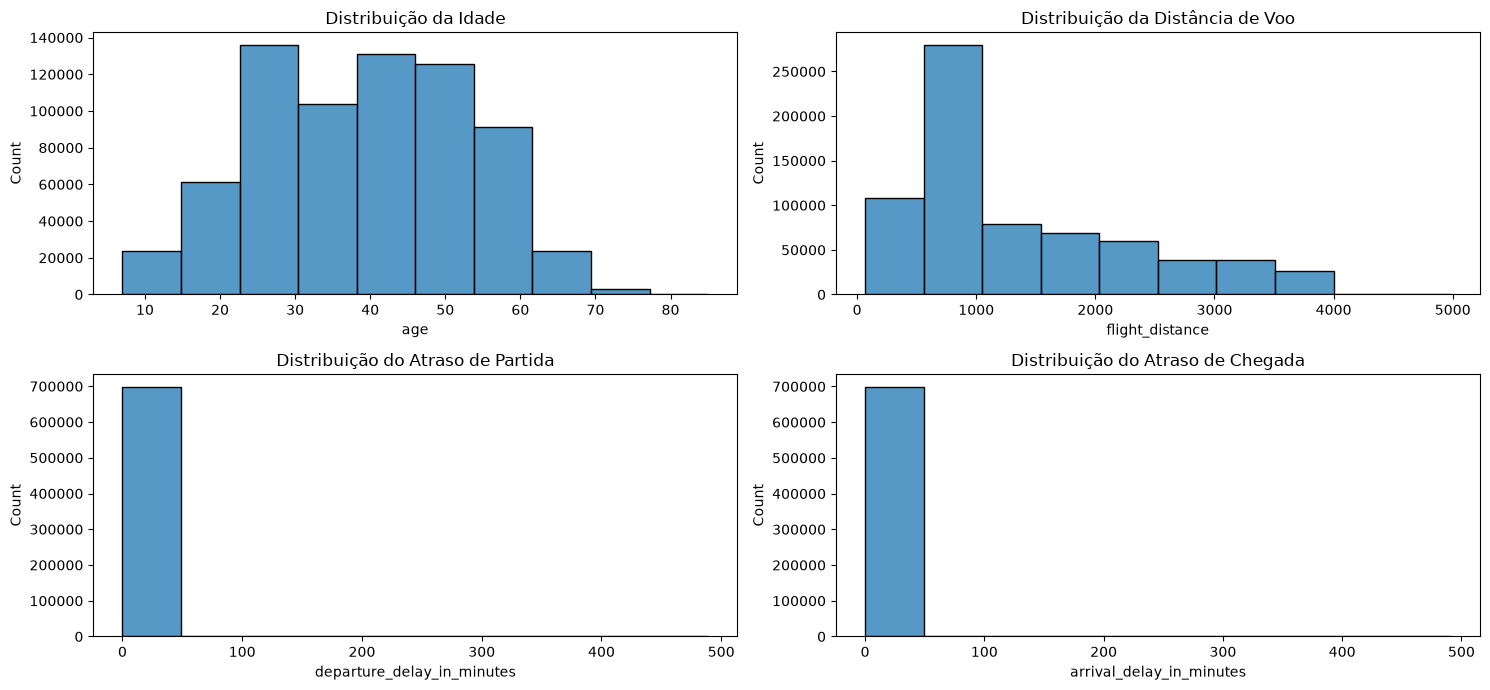

In [26]:
# Criar uma figura com 2 linhas e 2 colunas
fig, axes = plt.subplots(2, 2, figsize=(15, 7))

# Age
sns.histplot(df1['age'], bins=10, ax=axes[0, 0])
axes[0, 0].set_title('Distribuição da Idade')

# Distância de voo (flight distance)
sns.histplot(df1['flight_distance'], bins=10, ax=axes[0, 1])
axes[0, 1].set_title('Distribuição da Distância de Voo')

# Atraso de partida (departure delay)
sns.histplot(df1['departure_delay_in_minutes'], bins=10, ax=axes[1, 0])
axes[1, 0].set_title('Distribuição do Atraso de Partida')

# Atraso de chegada (arrival delay)
sns.histplot(df1['arrival_delay_in_minutes'], bins=10, ax=axes[1, 1])
axes[1, 1].set_title('Distribuição do Atraso de Chegada')

# Ajustar o espaçamento
plt.tight_layout()

# Exibir os gráficos
plt.show()

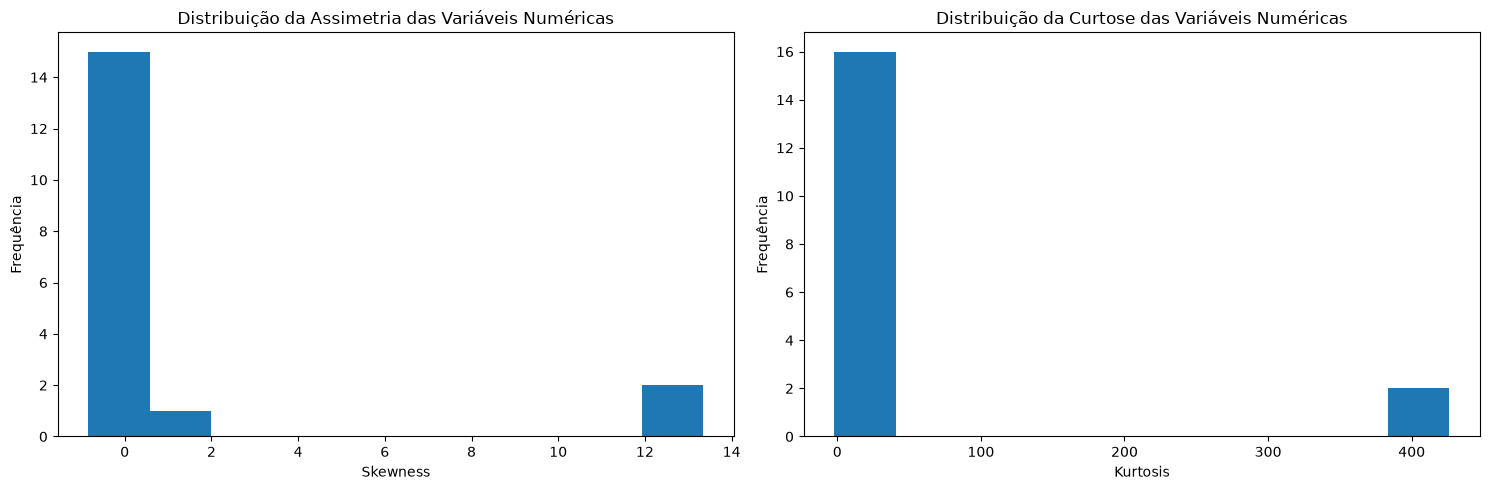

In [27]:
# Criar uma figura com 1 linha e 2 colunas
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histograma Skewness (Assimetria): negativo = cauda esquerda, positivo = cauda direita, 0 = simetria
axes[0].hist(d5.T.values.flatten(), bins=10)
axes[0].set_ylabel('Frequência')
axes[0].set_title('Distribuição da Assimetria das Variáveis Numéricas')
axes[0].set_xlabel('Skewness')

# Histograma Kurtosis (Curtose): relacionada ao comportamento das caudas e à ocorrência de valores extremos
axes[1].hist(d6.T.values.flatten(), bins=10)
axes[1].set_ylabel('Frequência')
axes[1].set_title('Distribuição da Curtose das Variáveis Numéricas')
axes[1].set_xlabel('Kurtosis')

# Ajustar o espaçamento
plt.tight_layout()

# Exibir os gráficos
plt.show()

## 1.7.2 Categorical Attributes

In [28]:
cat_attributes.apply(lambda x: x.unique().shape[0])

gender            2
customer_type     2
type_of_travel    2
class             3
dtype: int64

<Axes: xlabel='gender', ylabel='satisfaction'>

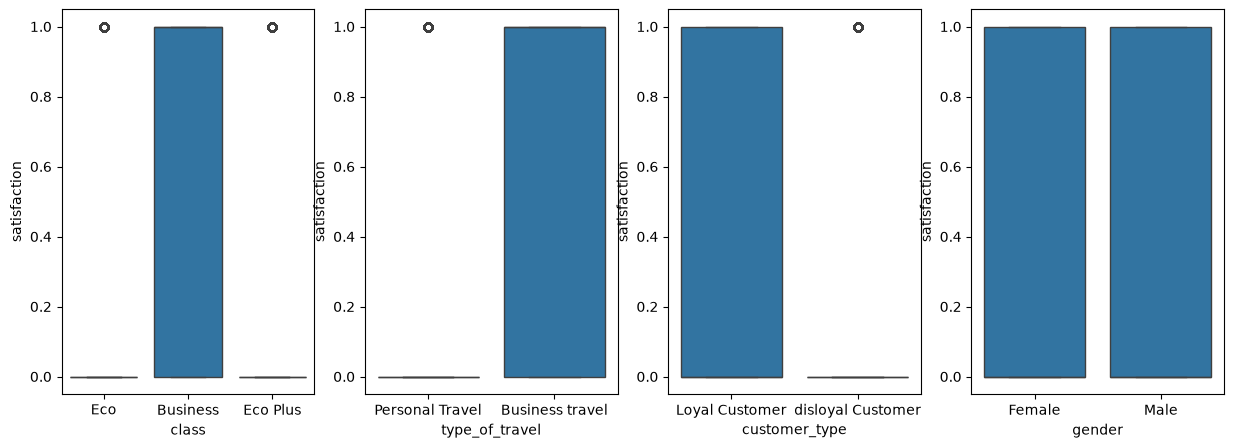

In [29]:
#boxplot
aux1 = pd.concat([cat_attributes, df1['satisfaction']], axis=1)

plt.figure(figsize=(15, 5))
plt.subplot(1, 4, 1)
sns.boxplot(x='class', y='satisfaction', data=aux1)

plt.subplot(1, 4, 2)
sns.boxplot(x='type_of_travel', y='satisfaction', data=aux1)

plt.subplot(1, 4, 3)
sns.boxplot(x='customer_type', y='satisfaction', data=aux1)

plt.subplot(1, 4, 4)
sns.boxplot(x='gender', y='satisfaction', data=aux1)

# 2.0 FEATURE ENGINEERING

## Mapa mental de hipóteses

- Fenômeno: Satisfação do cliente (variável dependente ou resposta = y).
- Agentes: Variáveis que impactam o fenômeno (variáveis independentes = x)
- Atributos do agente: características dos atributos.

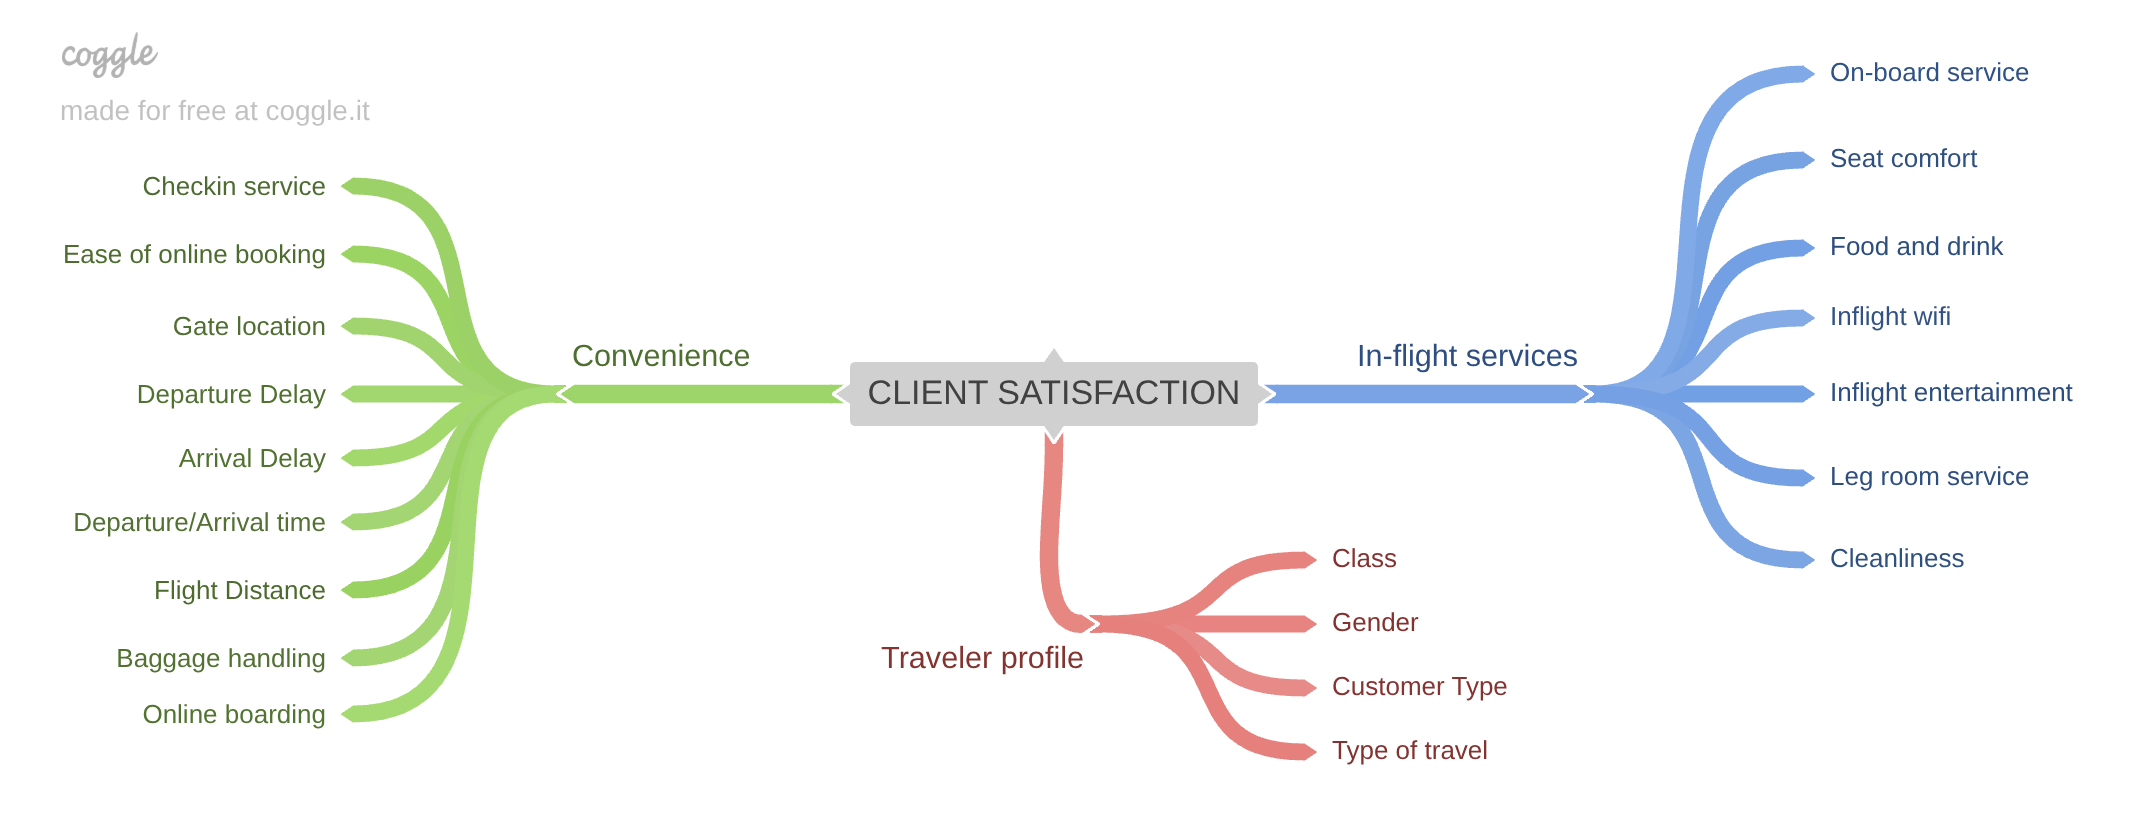

In [30]:
image('../img/client_satisfaction.png')

## 2.1 Criação das hipóteses

22 Hipóteses foram geradas considerando três frentes: conveniência, serviços a bordo e perfil do viajante.
Para vadiação ou refutação do teste de crenças.

### Hipóteses com dados disponíveis:
#### 2.1.1 Serviços de Conveniência

**1** Facilidade de autoserviço online de agendamento aumenta o nível de satisfação do cliente.

**2** Facilidade de autoserviço online de check-in aumenta o nível de satisfação do cliente.

**3** Facilidade de autoserviço online cartão de embarque aumenta o nível de satisfação do cliente.

**4** O atraso na saída ou na chegada do vôo diminuem a satisfação do cliente.

**5** A disponibilidade de vôos em horário conveniente de partida e chegada aumentam a satisfação do cliente.

**6** Distâncias maiores de vôo diminuem a satisfação do cliente.

**7** A localização do portão aumenta a satisfação do cliente.

**8** O serviço de manuseio de bagagem aumenta a satisfação do cliente.

#### 2.1.2 Serviços durante o vôo

**1** Quanto maior a satisfação com o serviço a bordo maior a satisfação do cliente.

**2** Quanto maior a satisfação com o conforto do assento maior a satisfação do cliente.

**3** Quanto maior a satisfação com o serviço de comida e bebida a bordo maior a satisfação do cliente.

**4** Quanto maior a satisfação com o serviço de wifi a bordo maior a satisfação do cliente.

**5** Quanto maior a satisfação com o serviço de entretenimento a bordo maior a satisfação do cliente.

**6** Quanto maior a satisfação com o serviço de espaço para as pernas maior a satisfação do cliente.

**7** Quanto maior a satisfação com o serviço de limpeza a bordo maior a satisfação do cliente.

#### 2.1.3 Perfil do Viajante

**1** Quanto maior a idade menor o nível de satisfação do cliente.

**2** O gênero feminino sente maior de satisfação em relação aos serviços abordo.

**3** A classe de viajante Business tem maior nível de satisfação.

**4** A classe de viajante Eco Plus tem maior nível de satisfação.

**5** A classe de viajante Eco tem menor nível de satisfação.

**6** O cliente fidelizado tem maior nível de satisfação.

**7** Viajantes a trabalho tem maior nível de satisfação.

## 2.2 Lista final de hipóteses

**1** Facilidade de autoserviço online de agendamento aumenta o nível de satisfação do cliente.

**2** O atraso na saída ou na chegada do vôo diminuem a satisfação do cliente.

**3** Distâncias maiores de vôo diminuem a satisfação do cliente.

**4** Quanto maior a satisfação com o serviço a bordo maior a satisfação do cliente.

**5** Quanto maior a satisfação com o serviço de wifi a bordo maior a satisfação do cliente.

**6** Quanto maior a satisfação com o serviço de entretenimento a bordo maior a satisfação do cliente.

**7** Quanto maior a satisfação com o conforto do assento maior a satisfação do cliente.

**8** Quanto maior a satisfação com o serviço de limpeza a bordo maior a satisfação do cliente.

**9** A classe de viajante Eco tem menor nível de satisfação.

**10** O cliente fidelizado tem maior nível de satisfação.

**11** Viajantes a trabalho tem maior nível de satisfação.

### Feature Engineering

In [31]:
df2 = df1.copy()
df2.dtypes

id                                     int64
age                                    int64
flight_distance                        int64
inflight_wifi_service                  int64
departure_arrival_time_convenient      int64
ease_of_online_booking                 int64
gate_location                          int64
food_and_drink                         int64
online_boarding                        int64
seat_comfort                           int64
inflight_entertainment                 int64
on_board_service                       int64
leg_room_service                       int64
baggage_handling                       int64
checkin_service                        int64
cleanliness                            int64
departure_delay_in_minutes             int64
arrival_delay_in_minutes             float64
gender                                   str
customer_type                            str
type_of_travel                           str
class                                    str
satisfacti

# 3.0 ANÁLISE EXPLORATÓRIA DOS DADOS - EDA

## 3.1 Análise Exploratória Univariada

### 3.1.1 Numerical Variable

array([[<Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'flight_distance'}>,
        <Axes: title={'center': 'inflight_wifi_service'}>,
        <Axes: title={'center': 'departure_arrival_time_convenient'}>],
       [<Axes: title={'center': 'ease_of_online_booking'}>,
        <Axes: title={'center': 'gate_location'}>,
        <Axes: title={'center': 'food_and_drink'}>,
        <Axes: title={'center': 'online_boarding'}>],
       [<Axes: title={'center': 'seat_comfort'}>,
        <Axes: title={'center': 'inflight_entertainment'}>,
        <Axes: title={'center': 'on_board_service'}>,
        <Axes: title={'center': 'leg_room_service'}>],
       [<Axes: title={'center': 'baggage_handling'}>,
        <Axes: title={'center': 'checkin_service'}>,
        <Axes: title={'center': 'cleanliness'}>,
        <Axes: title={'center': 'departure_delay_in_minutes'}>],
       [<Axes: title={'center': 'arrival_delay_in_minutes'}>,
        <Axes: title={'center': 'satisfaction'}>, <Axes:

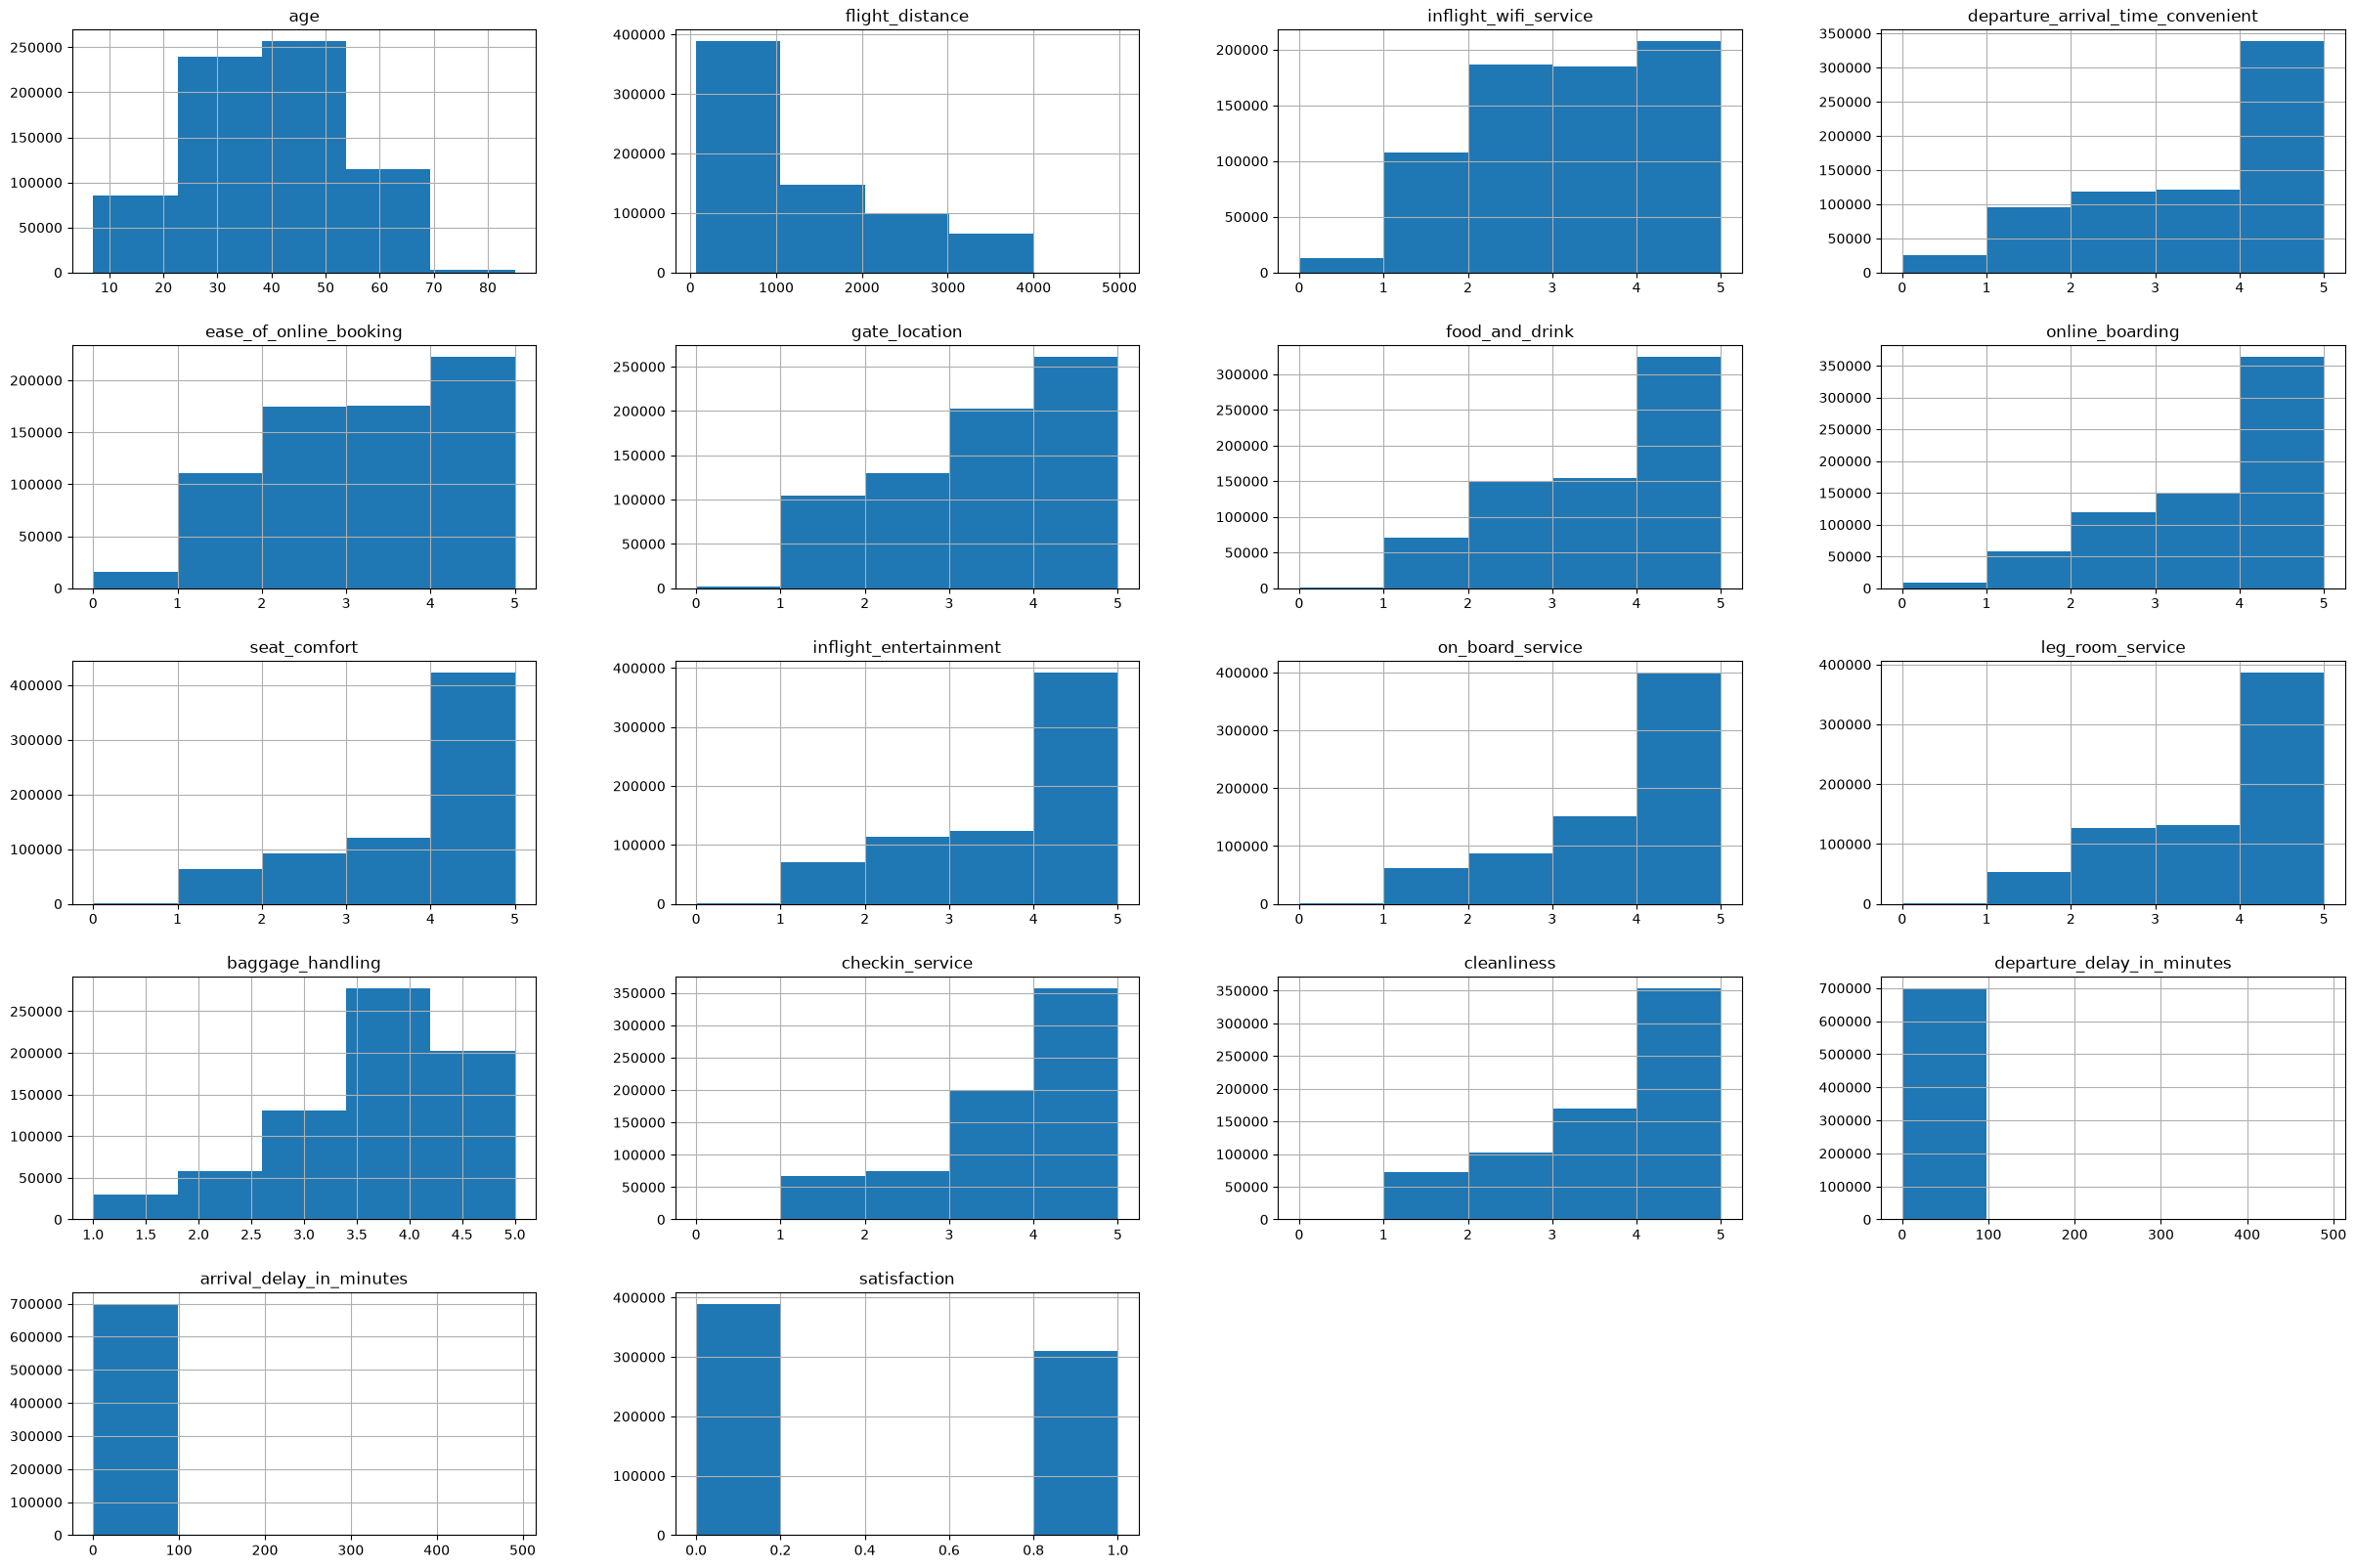

In [32]:
num_attributes.hist(bins=5, figsize=(30,20))

### 3.1.2 Categorical Variables

In [33]:
cat_attributes.head()

,gender,customer_type,type_of_travel,class
0,Female,Loyal Customer,Personal Travel,Eco
1,Male,Loyal Customer,Business travel,Business
2,Female,Loyal Customer,Personal Travel,Eco
3,Male,Loyal Customer,Personal Travel,Eco
4,Female,disloyal Customer,Business travel,Eco


In [34]:
cat_attributes.apply(lambda x: x.unique().shape[0])

gender            2
customer_type     2
type_of_travel    2
class             3
dtype: int64

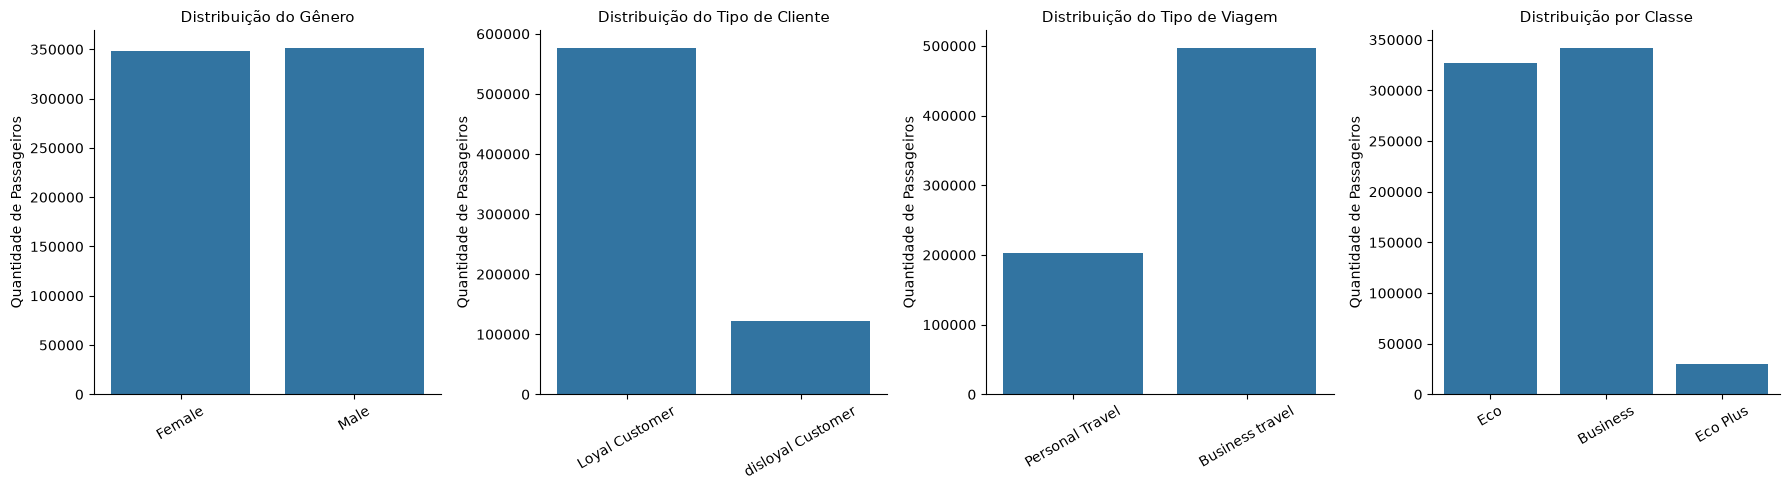

In [35]:
# Criar figura com 1 linha e 4 colunas
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

# Lista das variáveis e seus títulos
variaveis = ['gender', 'customer_type', 'type_of_travel', 'class']

titulos = [
    'Distribuição do Gênero',
    'Distribuição do Tipo de Cliente',
    'Distribuição do Tipo de Viagem',
    'Distribuição por Classe'
]

# Criar os gráficos
for ax, variavel, titulo in zip(axes, variaveis, titulos):

    sns.countplot(data=df2,x=variavel,ax=ax)
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel('')
    ax.set_ylabel('Quantidade de Passageiros')

    # Rotacionar rótulos, se necessário
    ax.tick_params(axis='x', rotation=30)

    # Remover bordas superiores e laterais
    sns.despine(ax=ax)

# Ajustar espaçamento
plt.tight_layout()

# Exibir os gráficos
plt.show()

## 3.2 Análise Exploratória Bivariada

### H1 Facilidade de autoserviço online de agendamento aumenta o nível de satisfação do cliente.

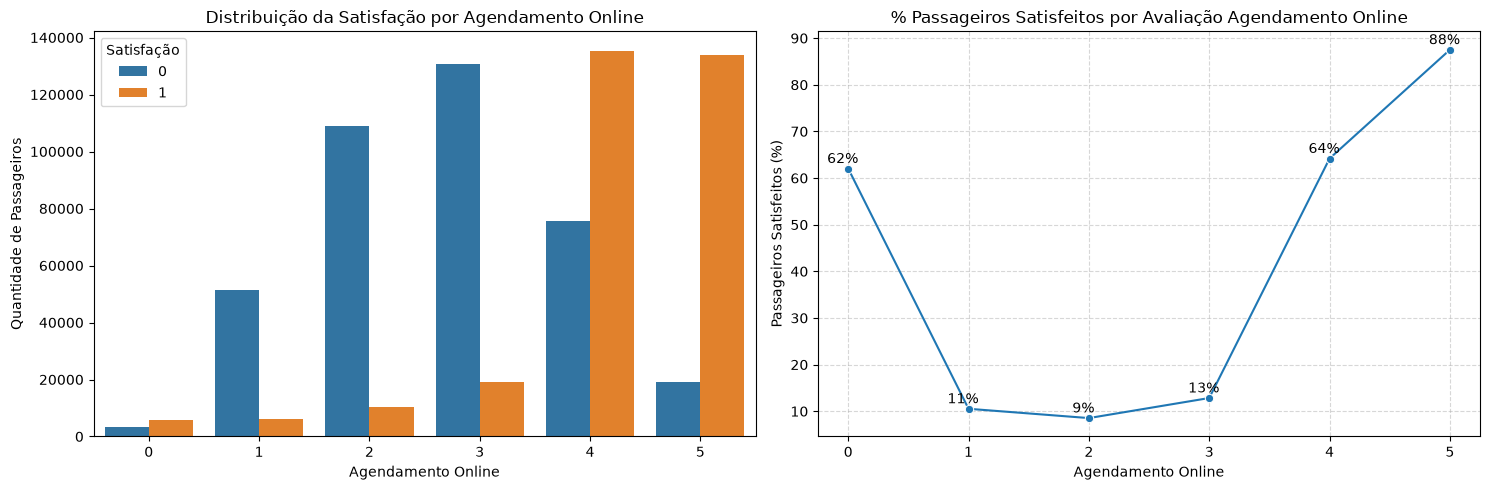

In [36]:
plt.figure(figsize=(15,5))

# Gráfico de agendamento online do vôo com Satisfação
plt.subplot( 1, 2 ,1)
sns.countplot(data=df2, x='online_boarding',hue='satisfaction')
plt.title('Distribuição da Satisfação por Agendamento Online')
plt.xlabel('Agendamento Online')
plt.ylabel('Quantidade de Passageiros')
plt.legend(title='Satisfação')

plt.subplot( 1, 2 ,2)
# Calcular a porcentagem de passageiros satisfeitos por nota
df_plot = (df2.groupby('online_boarding').apply(lambda x: (x['satisfaction'] == 1).mean()*100,include_groups=False).reset_index(name='satisfacao_percentual'))
# Criar o gráfico de linha com a porcentagem de passageiros satisfeitos por nota
sns.lineplot(data=df_plot, x='online_boarding', y='satisfacao_percentual',marker='o')
# Exibir o valor de cada ponto
for x, y in zip(df_plot['online_boarding'],df_plot['satisfacao_percentual']):
  plt.annotate(f'{y:.0f}%',(x, y),textcoords='offset points',xytext=(-4, 4),ha='center')
plt.title('% Passageiros Satisfeitos por Avaliação Agendamento Online')
plt.xlabel('Agendamento Online')
plt.ylabel('Passageiros Satisfeitos (%)')
plt.xticks(sorted(df2['online_boarding'].dropna().unique()))
plt.grid(True, linestyle='--', alpha=0.5)

# Ajustar o layout
plt.tight_layout()

# Exibir os gráficos
plt.show()

### H2 O atraso na saída ou na chegada do vôo diminuem a satisfação do cliente.

**VERDADEIRA** O atraso na saída ou na chegada do vôo diminuem a satisfação do cliente.

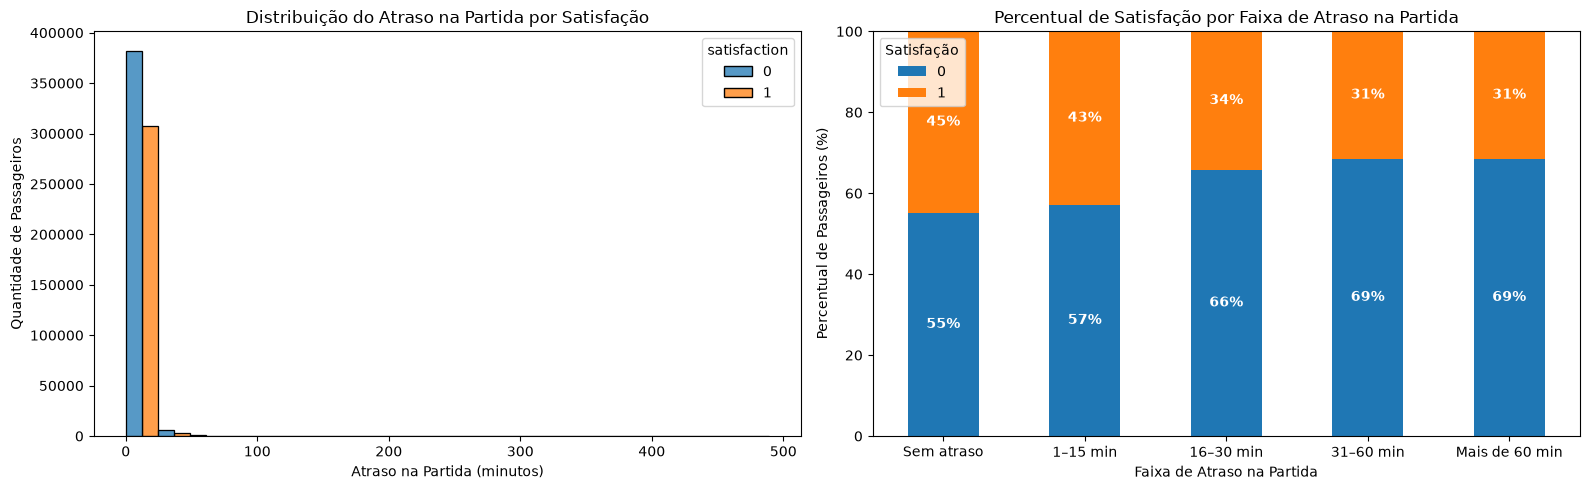

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Gráfico 1: Distribuição do atraso na partida
sns.histplot(data=df2,x='departure_delay_in_minutes',hue='satisfaction',bins=20,multiple='dodge',ax=axes[0])
axes[0].set_title('Distribuição do Atraso na Partida por Satisfação')
axes[0].set_xlabel('Atraso na Partida (minutos)')
axes[0].set_ylabel('Quantidade de Passageiros')

# Gráfico 2: Percentual de satisfação por faixa
# Criar faixas de atraso
limites = [-1, 0, 15, 30, 60, float('inf')]
rotulos = ['Sem atraso','1–15 min','16–30 min','31–60 min','Mais de 60 min']
df2['faixa_atraso_partida'] = pd.cut(df2['departure_delay_in_minutes'],bins=limites,labels=rotulos)

# Calcular percentual de cada categoria de satisfação
prop = pd.crosstab(df2['faixa_atraso_partida'],df2['satisfaction'],normalize='index') * 100

# Criar gráfico de barras empilhadas
prop.plot(kind='bar',stacked=True,ax=axes[1])

# Adicionar percentuais dentro das barras
for container in axes[1].containers:
    labels = [f'{v:.0f}%' if v >= 5 else''for v in container.datavalues]
    axes[1].bar_label(container,labels=labels,label_type='center',color='white',fontweight='bold')
axes[1].set_title('Percentual de Satisfação por Faixa de Atraso na Partida')
axes[1].set_xlabel('Faixa de Atraso na Partida')
axes[1].set_ylabel('Percentual de Passageiros (%)')
axes[1].set_ylim(0, 100)
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Satisfação')

plt.tight_layout()
plt.show()

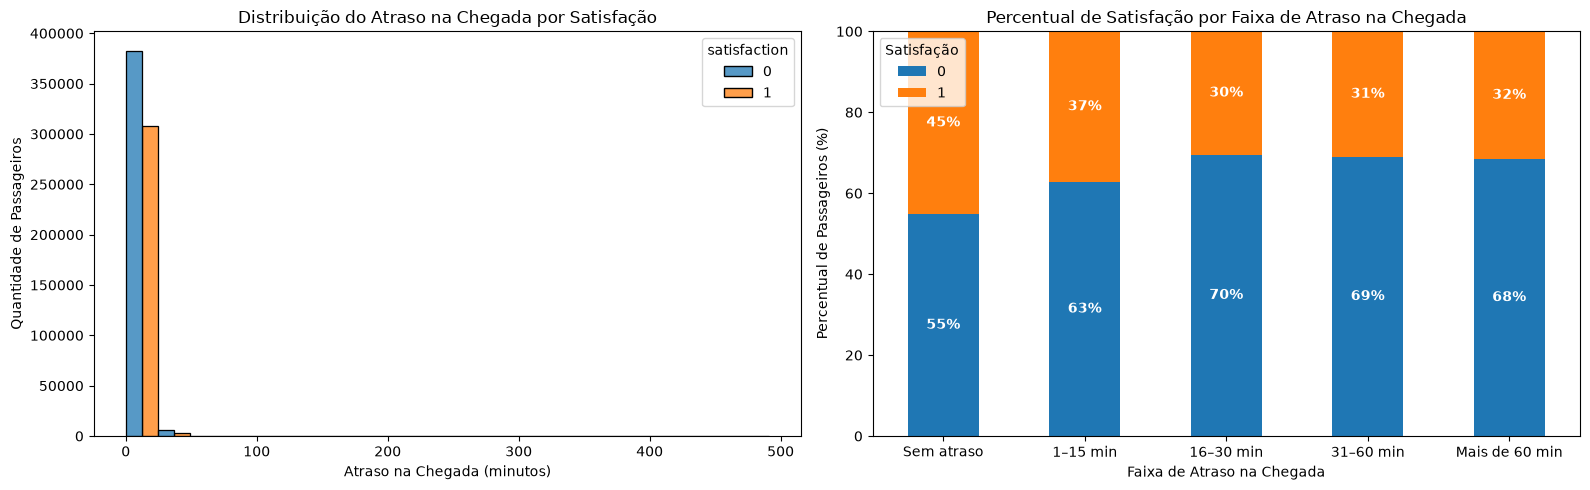

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Gráfico 1: Distribuição do atraso na chegada
sns.histplot(data=df2,x='arrival_delay_in_minutes',hue='satisfaction',bins=20,multiple='dodge',ax=axes[0])
axes[0].set_title('Distribuição do Atraso na Chegada por Satisfação')
axes[0].set_xlabel('Atraso na Chegada (minutos)')
axes[0].set_ylabel('Quantidade de Passageiros')

# Gráfico 2: Percentual de satisfação por faixa
# Criar faixas de atraso
limites = [-1, 0, 15, 30, 60, float('inf')]
rotulos = ['Sem atraso','1–15 min','16–30 min','31–60 min','Mais de 60 min']

df2['faixa_atraso_chegada'] = pd.cut(df2['arrival_delay_in_minutes'],bins=limites,labels=rotulos)

# Calcular percentual de cada categoria de satisfação
prop = pd.crosstab(df2['faixa_atraso_chegada'],df2['satisfaction'],normalize='index') * 100

# Criar gráfico de barras empilhadas
prop.plot(kind='bar',stacked=True,ax=axes[1])

# Adicionar percentuais dentro das barras
for container in axes[1].containers:
    labels = [f'{v:.0f}%' if v >= 5 else ''for v in container.datavalues]

    axes[1].bar_label(container,labels=labels,label_type='center',color='white',fontweight='bold')
axes[1].set_title('Percentual de Satisfação por Faixa de Atraso na Chegada')
axes[1].set_xlabel('Faixa de Atraso na Chegada')
axes[1].set_ylabel('Percentual de Passageiros (%)')
axes[1].set_ylim(0, 100)
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Satisfação')

plt.tight_layout()
plt.show()

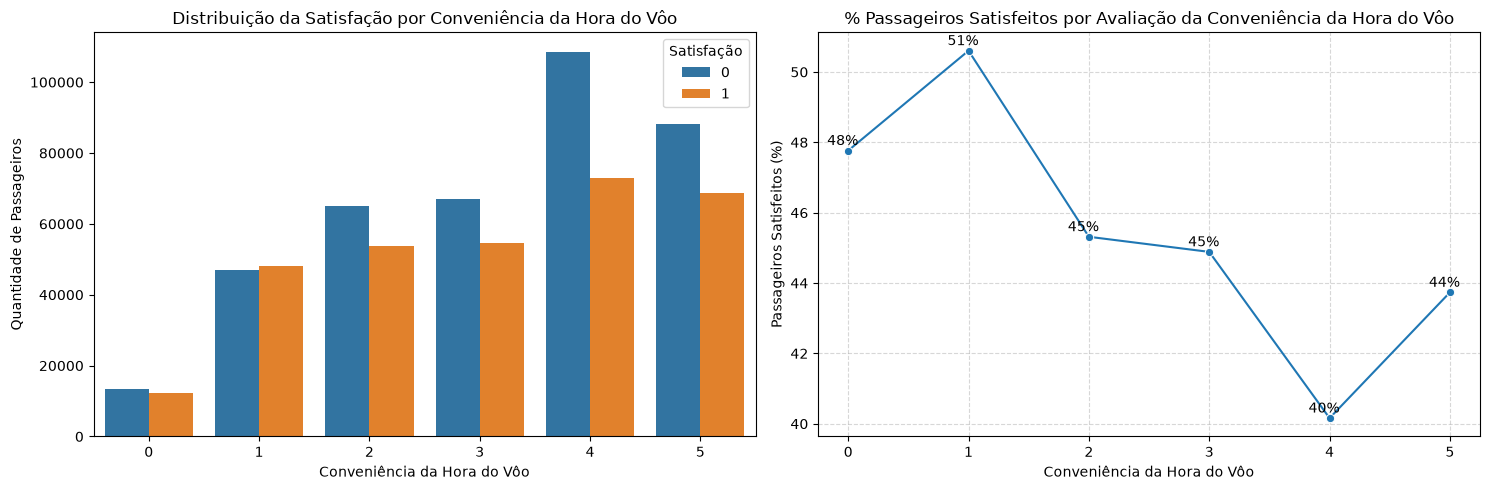

In [39]:
plt.figure(figsize=(15,5))

# Gráfico de Conveniência da Hora do Vôo com Satisfação
plt.subplot( 1, 2 ,1)
sns.countplot(data=df2, x='departure_arrival_time_convenient',hue='satisfaction')
plt.title('Distribuição da Satisfação por Conveniência da Hora do Vôo')
plt.xlabel('Conveniência da Hora do Vôo')
plt.ylabel('Quantidade de Passageiros')
plt.legend(title='Satisfação')

plt.subplot( 1, 2 ,2)
# Calcular a porcentagem de passageiros satisfeitos por nota
df_plot = (df2.groupby('departure_arrival_time_convenient').apply(lambda x: (x['satisfaction'] == 1).mean()*100,include_groups=False).reset_index(name='satisfacao_percentual'))
# Criar o gráfico de linha com a porcentagem de passageiros satisfeitos por nota
sns.lineplot(data=df_plot, x='departure_arrival_time_convenient', y='satisfacao_percentual',marker='o')
# Exibir o valor de cada ponto
for x, y in zip(df_plot['departure_arrival_time_convenient'],df_plot['satisfacao_percentual']):
  plt.annotate(f'{y:.0f}%',(x, y),textcoords='offset points',xytext=(-4, 4),ha='center')
plt.title('% Passageiros Satisfeitos por Avaliação da Conveniência da Hora do Vôo')
plt.xlabel('Conveniência da Hora do Vôo')
plt.ylabel('Passageiros Satisfeitos (%)')
plt.xticks(sorted(df2['departure_arrival_time_convenient'].dropna().unique()))
plt.grid(True, linestyle='--', alpha=0.5)

# Ajustar o layout
plt.tight_layout()

# Exibir os gráficos
plt.show()

### H3 Distâncias maiores de vôo diminuem a satisfação do cliente.

**FALSA** Distâncias maiores de vôo não diminuem a satisfação do cliente.

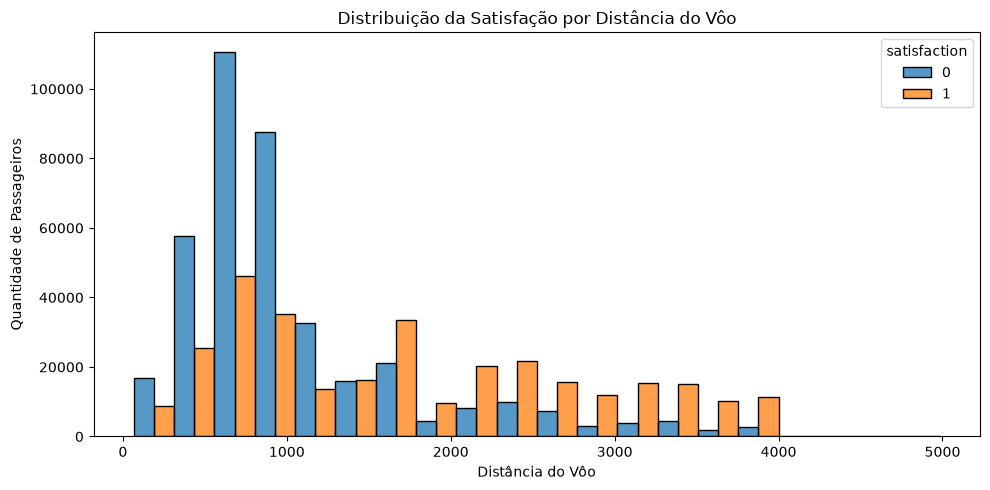

In [40]:
# Histograma da distância do voo com a satisfação
plt.figure(figsize=(10,5))
sns.histplot(data=df2, x='flight_distance', hue='satisfaction',bins=20, multiple='dodge')
plt.title('Distribuição da Satisfação por Distância do Vôo')
plt.xlabel('Distância do Vôo')
plt.ylabel('Quantidade de Passageiros')

plt.tight_layout()
plt.show()


<Figure size 500x500 with 0 Axes>

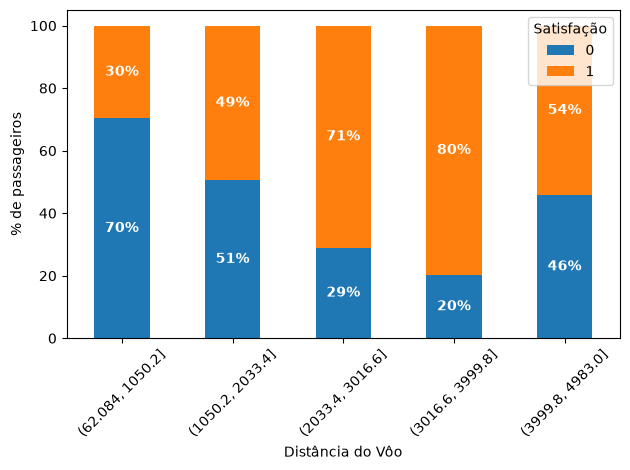

In [41]:
#proporção de satisfeitos por faixa
plt.figure(figsize=(5,5))
faixas = pd.cut(df2['flight_distance'], bins=5)
prop = pd.crosstab(faixas, df2['satisfaction'], normalize='index') * 100
ax = prop.plot(kind='bar', stacked=True)

# Porcentagem dentro de cada segmento das barras
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%', label_type='center',color='white', fontweight='bold')

plt.ylabel('% de passageiros')
plt.xlabel('Distância do Vôo')
plt.xticks(rotation=45)
plt.legend(title='Satisfação')

plt.tight_layout()
plt.show()


### H4 Quanto maior a satisfação com o serviço a bordo maior a satisfação do cliente.

**VERDADEIRA** Quanto maior a satisfação com o serviçoa bordo maior a satisfação do cliente.

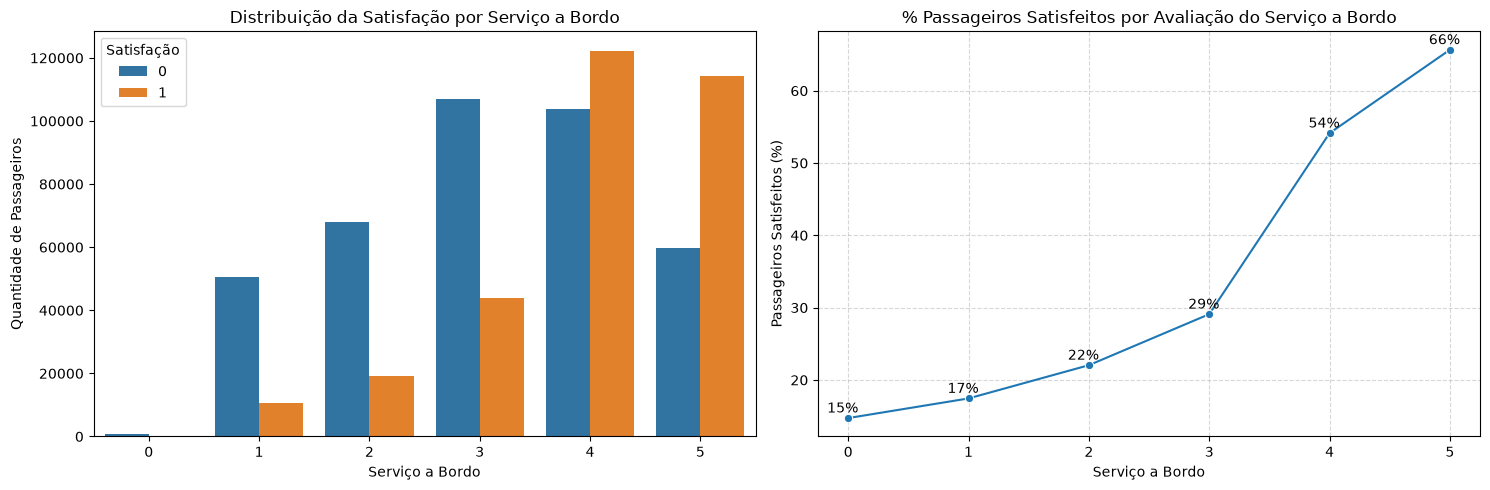

In [42]:
plt.figure(figsize=(15,5))

# Gráfico de atraso do vôo com Satisfação
plt.subplot( 1, 2 ,1)
sns.countplot(data=df2, x='on_board_service',hue='satisfaction')
plt.title('Distribuição da Satisfação por Serviço a Bordo')
plt.xlabel('Serviço a Bordo')
plt.ylabel('Quantidade de Passageiros')
plt.legend(title='Satisfação')

plt.subplot( 1, 2 ,2)
# Calcular a porcentagem de passageiros satisfeitos por nota
df_plot = (df2.groupby('on_board_service').apply(lambda x: (x['satisfaction'] == 1).mean()*100,include_groups=False).reset_index(name='satisfacao_percentual'))
# Criar o gráfico de linha com a porcentagem de passageiros satisfeitos por nota
sns.lineplot(data=df_plot, x='on_board_service', y='satisfacao_percentual',marker='o')
# Exibir o valor de cada ponto
for x, y in zip(df_plot['on_board_service'],df_plot['satisfacao_percentual']):
  plt.annotate(f'{y:.0f}%',(x, y),textcoords='offset points',xytext=(-4, 4),ha='center')
plt.title('% Passageiros Satisfeitos por Avaliação do Serviço a Bordo')
plt.xlabel('Serviço a Bordo')
plt.ylabel('Passageiros Satisfeitos (%)')
plt.xticks(sorted(df2['on_board_service'].dropna().unique()))
plt.grid(True, linestyle='--', alpha=0.5)

# Ajustar o layout
plt.tight_layout()

# Exibir os gráficos
plt.show()

### H5 Quanto maior a satisfação com o serviço de wifi a bordo maior a satisfação do cliente.

**VERDADEIRA** Quanto maior a satisfação com serviço de wifi a bordo maior a satisfação do cliente.

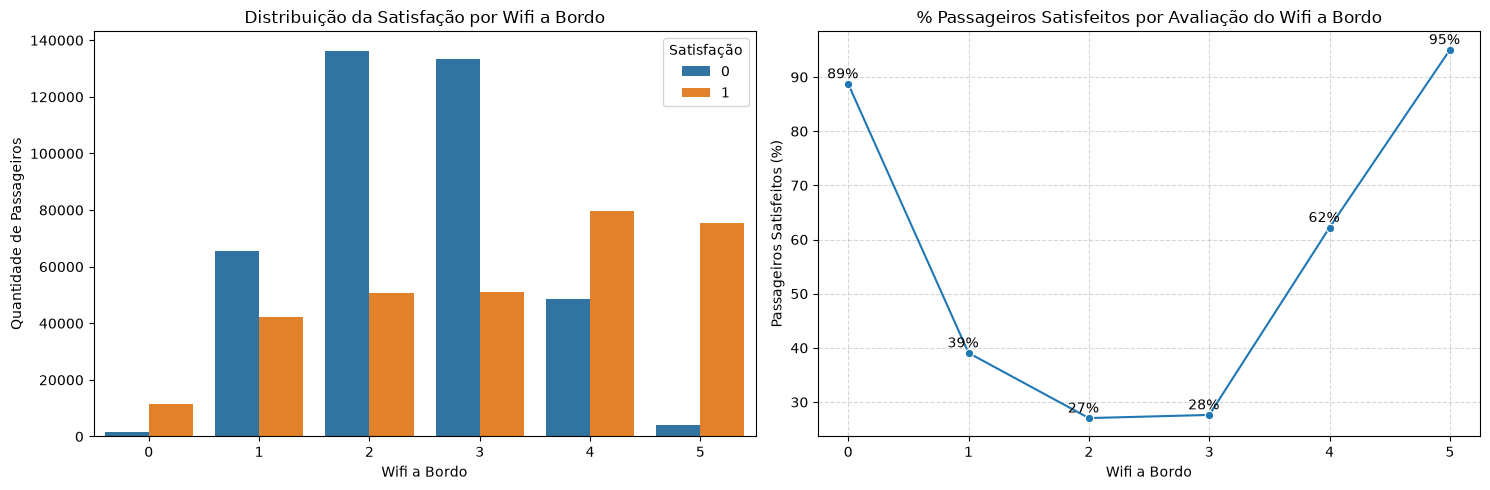

In [43]:
plt.figure(figsize=(15,5))

# Gráfico de Wifi a bordo com Satisfação
plt.subplot( 1, 2 ,1)
sns.countplot(data=df2, x='inflight_wifi_service',hue='satisfaction')
plt.title('Distribuição da Satisfação por Wifi a Bordo')
plt.xlabel('Wifi a Bordo')
plt.ylabel('Quantidade de Passageiros')
plt.legend(title='Satisfação')

plt.subplot( 1, 2 ,2)
# Calcular a porcentagem de passageiros satisfeitos por nota
df_plot = (df2.groupby('inflight_wifi_service').apply(lambda x: (x['satisfaction'] == 1).mean()*100,include_groups=False).reset_index(name='satisfacao_percentual'))
# Criar o gráfico de linha com a porcentagem de passageiros satisfeitos por nota
sns.lineplot(data=df_plot, x='inflight_wifi_service', y='satisfacao_percentual',marker='o')
# Exibir o valor de cada ponto
for x, y in zip(df_plot['inflight_wifi_service'],df_plot['satisfacao_percentual']):
  plt.annotate(f'{y:.0f}%',(x, y),textcoords='offset points',xytext=(-4, 4),ha='center')
plt.title('% Passageiros Satisfeitos por Avaliação do Wifi a Bordo')
plt.xlabel('Wifi a Bordo')
plt.ylabel('Passageiros Satisfeitos (%)')
plt.xticks(sorted(df2['inflight_wifi_service'].dropna().unique()))
plt.grid(True, linestyle='--', alpha=0.5)

# Ajustar o layout
plt.tight_layout()

# Exibir os gráficos
plt.show()

### H6 Quanto maior a satisfação com o serviço de entretenimento a bordo maior a satisfação do cliente.

**VERDADEIRA** Quanto maior a satisfação com o serviço deentretenimento a bordo maior a satisfação do cliente.

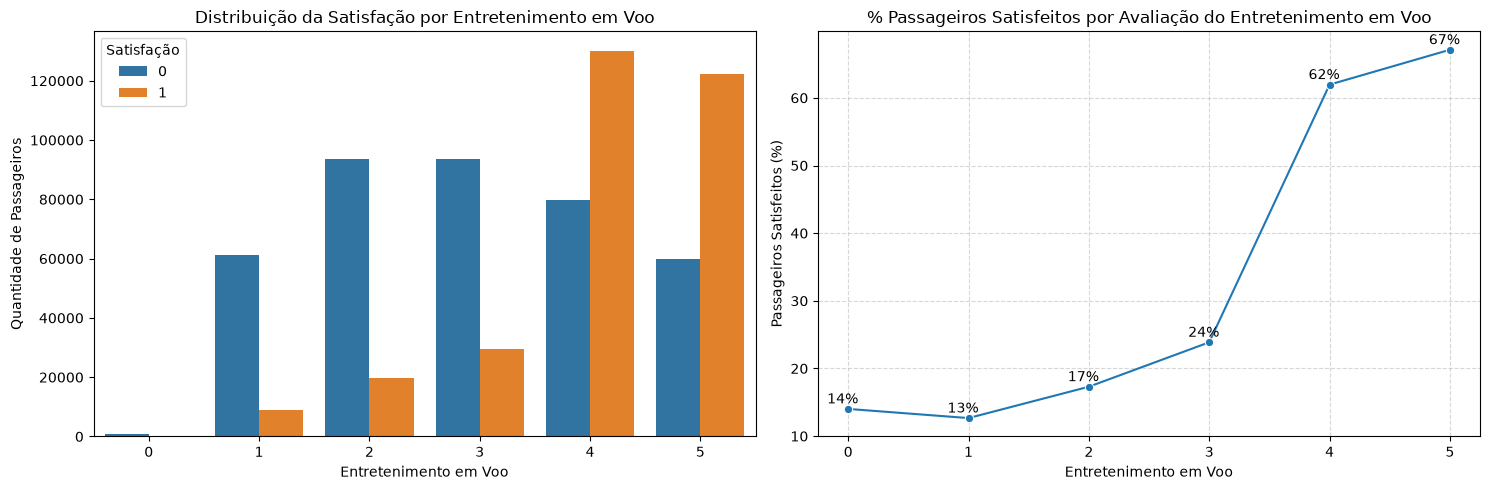

In [44]:
plt.figure(figsize=(15,5))

# Gráfico de atraso do vôo com Satisfação
plt.subplot( 1, 2 ,1)
sns.countplot(data=df2, x='inflight_entertainment',hue='satisfaction')
plt.title('Distribuição da Satisfação por Entretenimento em Voo')
plt.xlabel('Entretenimento em Voo')
plt.ylabel('Quantidade de Passageiros')
plt.legend(title='Satisfação')

plt.subplot( 1, 2 ,2)
# Calcular a porcentagem de passageiros satisfeitos por nota
df_plot = (df2.groupby('inflight_entertainment').apply(lambda x: (x['satisfaction'] == 1).mean()*100,include_groups=False).reset_index(name='satisfacao_percentual'))
# Criar o gráfico de linha com a porcentagem de passageiros satisfeitos por nota
sns.lineplot(data=df_plot, x='inflight_entertainment', y='satisfacao_percentual',marker='o')
# Exibir o valor de cada ponto
for x, y in zip(df_plot['inflight_entertainment'],df_plot['satisfacao_percentual']):
  plt.annotate(f'{y:.0f}%',(x, y),textcoords='offset points',xytext=(-4, 4),ha='center')
plt.title('% Passageiros Satisfeitos por Avaliação do Entretenimento em Voo')
plt.xlabel('Entretenimento em Voo')
plt.ylabel('Passageiros Satisfeitos (%)')
plt.xticks(sorted(df2['inflight_entertainment'].dropna().unique()))
plt.grid(True, linestyle='--', alpha=0.5)

# Ajustar o layout
plt.tight_layout()

# Exibir os gráficos
plt.show()

### H7 Quanto maior a satisfação com o conforto do assento maior a satisfação do cliente.

**VERDADEIRA** Quanto maior a satisfação com o conforto do assento maior a satisfação do cliente.

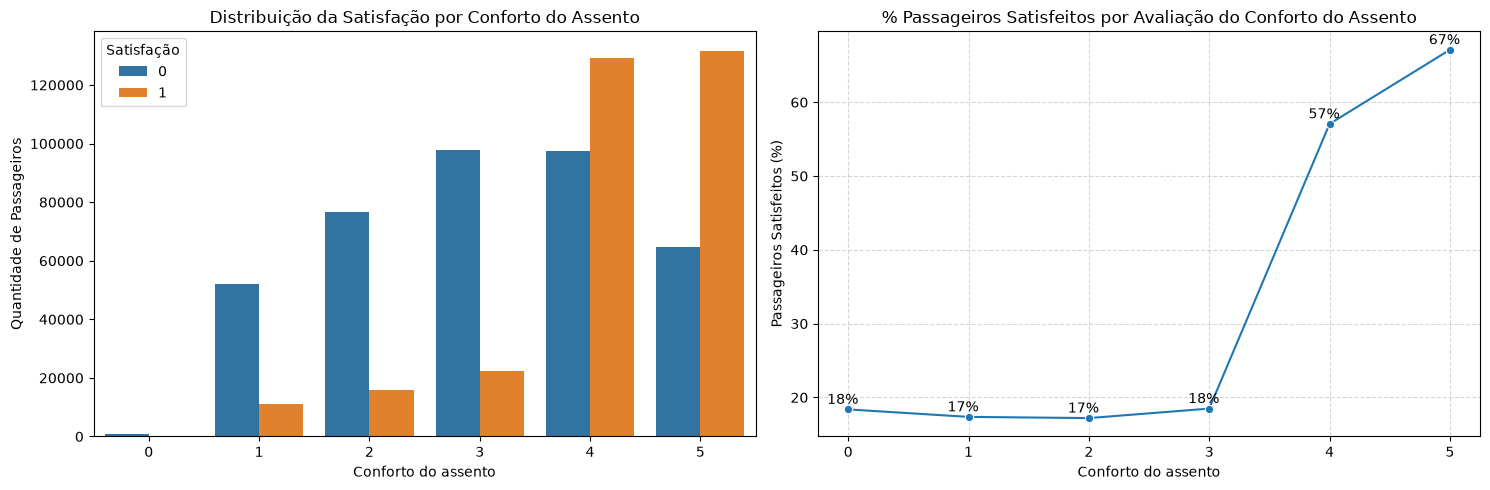

In [45]:
plt.figure(figsize=(15,5))

# Gráfico de Conforto do Assento com Satisfação
plt.subplot( 1, 2 ,1)
sns.countplot(data=df2, x='seat_comfort',hue='satisfaction')
plt.title('Distribuição da Satisfação por Conforto do Assento')
plt.xlabel('Conforto do assento')
plt.ylabel('Quantidade de Passageiros')
plt.legend(title='Satisfação')

plt.subplot( 1, 2 ,2)
# Calcular a porcentagem de passageiros satisfeitos por nota
df_plot = (df2.groupby('seat_comfort').apply(lambda x: (x['satisfaction'] == 1).mean()*100,include_groups=False).reset_index(name='satisfacao_percentual'))
# Criar o gráfico de linha com a porcentagem de passageiros satisfeitos por nota
sns.lineplot(data=df_plot, x='seat_comfort', y='satisfacao_percentual',marker='o')
# Exibir o valor de cada ponto
for x, y in zip(df_plot['seat_comfort'],df_plot['satisfacao_percentual']):
  plt.annotate(f'{y:.0f}%',(x, y),textcoords='offset points',xytext=(-4, 4),ha='center')
plt.title('% Passageiros Satisfeitos por Avaliação do Conforto do Assento')
plt.xlabel('Conforto do assento')
plt.ylabel('Passageiros Satisfeitos (%)')
plt.xticks(sorted(df2['seat_comfort'].dropna().unique()))
plt.grid(True, linestyle='--', alpha=0.5)

# Ajustar o layout
plt.tight_layout()

# Exibir os gráficos
plt.show()

### H8 Quanto maior a satisfação com o serviço de limpeza a bordo maior a satisfação do cliente.

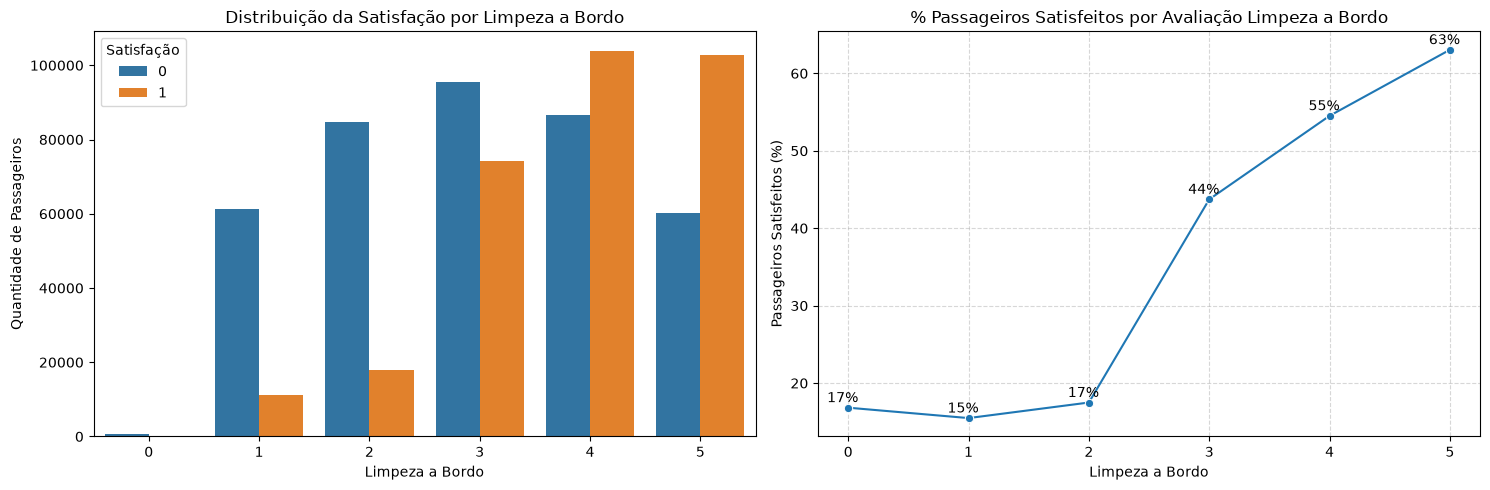

In [46]:
plt.figure(figsize=(15,5))

# Gráfico de Limpeza a Bordo com Satisfação
plt.subplot( 1, 2 ,1)
sns.countplot(data=df2, x='cleanliness',hue='satisfaction')
plt.title('Distribuição da Satisfação por Limpeza a Bordo')
plt.xlabel('Limpeza a Bordo')
plt.ylabel('Quantidade de Passageiros')
plt.legend(title='Satisfação')

plt.subplot( 1, 2 ,2)
# Calcular a porcentagem de passageiros satisfeitos por nota
df_plot = (df2.groupby('cleanliness').apply(lambda x: (x['satisfaction'] == 1).mean()*100,include_groups=False).reset_index(name='satisfacao_percentual'))
# Criar o gráfico de linha com a porcentagem de passageiros satisfeitos por nota
sns.lineplot(data=df_plot, x='cleanliness', y='satisfacao_percentual',marker='o')
# Exibir o valor de cada ponto
for x, y in zip(df_plot['cleanliness'],df_plot['satisfacao_percentual']):
  plt.annotate(f'{y:.0f}%',(x, y),textcoords='offset points',xytext=(-4, 4),ha='center')
plt.title('% Passageiros Satisfeitos por Avaliação Limpeza a Bordo')
plt.xlabel('Limpeza a Bordo')
plt.ylabel('Passageiros Satisfeitos (%)')
plt.xticks(sorted(df2['cleanliness'].dropna().unique()))
plt.grid(True, linestyle='--', alpha=0.5)

# Ajustar o layout
plt.tight_layout()

# Exibir os gráficos
plt.show()

### H9 A classe de viajante Eco tem menor nível de satisfação.

 **VERDADEIRA** A classe de viajante ECO tem menor nível de satisfação.

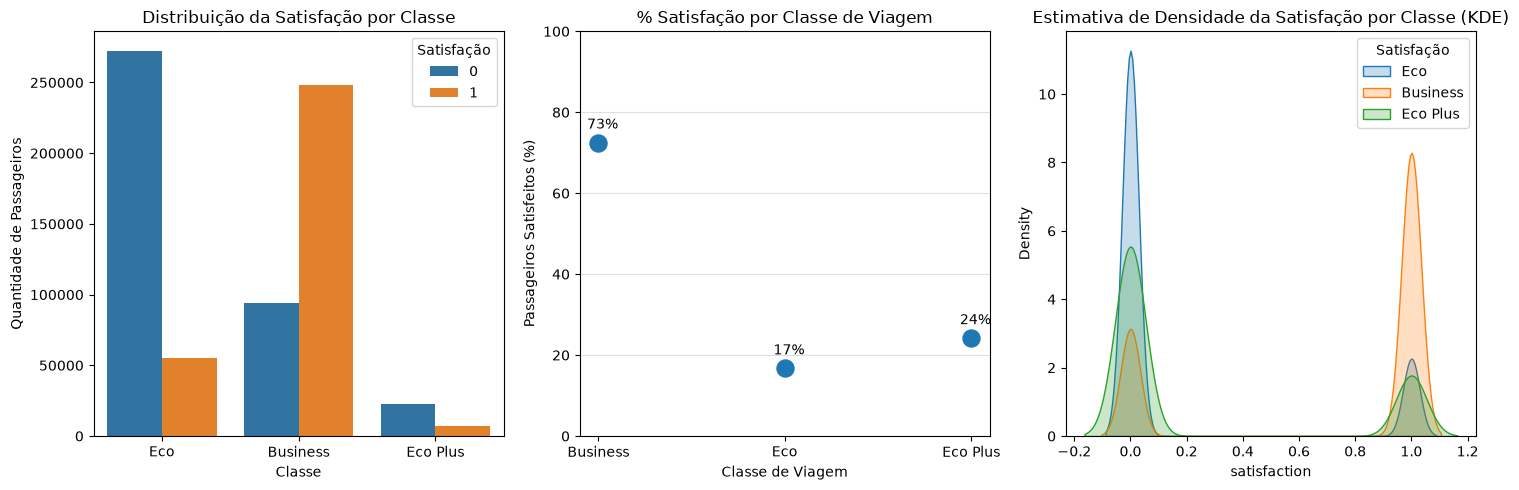

In [47]:
plt.figure(figsize=(15,5))

# Gráfico de Classe com Satisfação
plt.subplot( 1, 3 ,1)
sns.countplot(data=df2, x='class',hue='satisfaction')
plt.title('Distribuição da Satisfação por Classe')
plt.xlabel('Classe')
plt.ylabel('Quantidade de Passageiros')
plt.legend(title='Satisfação')

# Gráfico de pontos Classe com Satisfação
plt.subplot( 1, 3 ,2)
# Calcular a taxa de satisfação por classe
resultado = (df2.groupby('class').apply(lambda x: (x['satisfaction'] == 1).mean()*100, include_groups=False).reset_index(name='satisfacao_percentual'))
# Criar o gráfico de dispersão com a taxa de satisfação por classe
plt.scatter(resultado['class'],resultado['satisfacao_percentual'],s=150)
# Mostrar o percentual acima de cada ponto
for _, row in resultado.iterrows():
    plt.annotate(f"{row['satisfacao_percentual']:.0f}%",(row['class'], row['satisfacao_percentual']),xytext=(3, 10),textcoords='offset points',ha='center')

plt.title('% Satisfação por Classe de Viagem')
plt.xlabel('Classe de Viagem')
plt.ylabel('Passageiros Satisfeitos (%)')
plt.ylim(0, 100)
plt.grid(axis='y', alpha=0.4)

# Gráfico de Classe com Satisfação (KDE)
plt.subplot( 1, 3 ,3)
sns.kdeplot( df2[df2['class'] == 'Eco']['satisfaction'], label='Eco', fill=True )
sns.kdeplot( df2[df2['class'] == 'Business']['satisfaction'], label='Business', fill=True )
sns.kdeplot( df2[df2['class'] == 'Eco Plus']['satisfaction'], label='Eco Plus', fill=True )
plt.title('Estimativa de Densidade da Satisfação por Classe (KDE)')
plt.legend(title='Satisfação')

# Ajustar o layout
plt.tight_layout()

# Exibir os gráficos
plt.show()

### H10 O cliente fidelizado tem maior nível de satisfação.

**VERDADEIRA** O cliente fidelizado tem maior nível de satisfação.

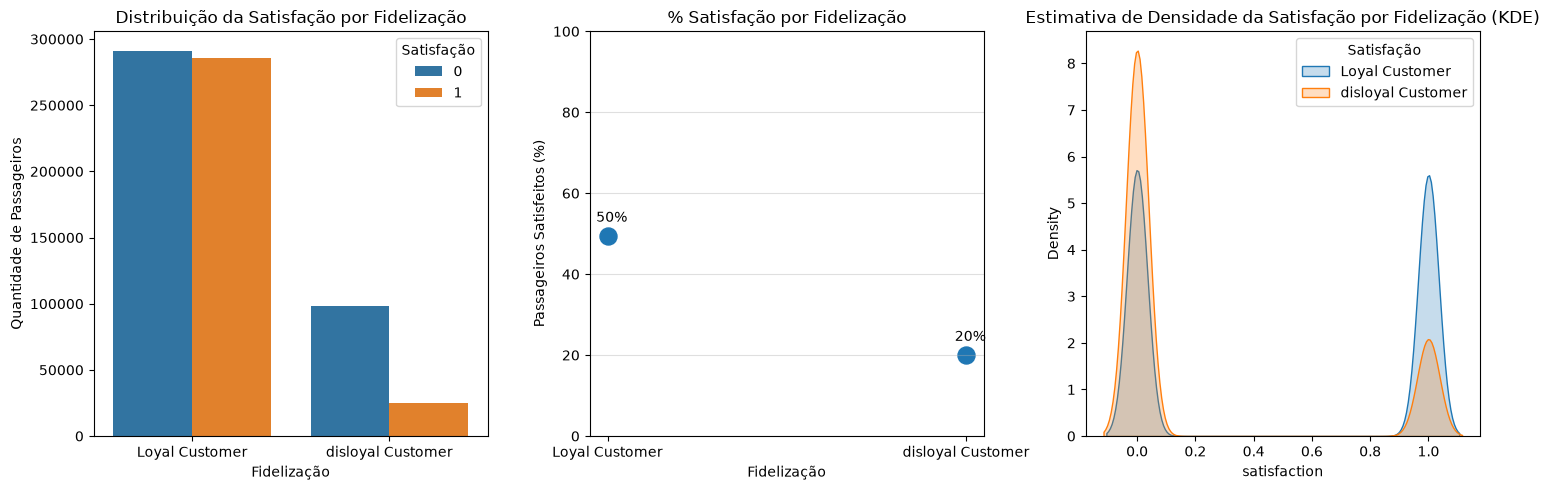

In [48]:
plt.figure(figsize=(15,5))

# Gráfico de Fidelização com Satisfação
plt.subplot( 1, 3 ,1)
sns.countplot(data=df2, x='customer_type',hue='satisfaction')
plt.title('Distribuição da Satisfação por Fidelização')
plt.xlabel('Fidelização')
plt.ylabel('Quantidade de Passageiros')
plt.legend(title='Satisfação')

# Gráfico de pontos Fidelização com Satisfação
plt.subplot( 1, 3 ,2)
# Calcular a taxa de satisfação por Fidelização
resultado = (df2.groupby('customer_type').apply(lambda x: (x['satisfaction'] == 1).mean()*100, include_groups=False).reset_index(name='satisfacao_percentual'))
# Criar o gráfico de dispersão com a taxa de satisfação por Fidelização
plt.scatter(resultado['customer_type'],resultado['satisfacao_percentual'],s=150)
# Mostrar o percentual acima de cada ponto
for _, row in resultado.iterrows():
    plt.annotate(f"{row['satisfacao_percentual']:.0f}%",(row['customer_type'], row['satisfacao_percentual']),xytext=(3, 10),textcoords='offset points',ha='center')

plt.title('% Satisfação por Fidelização')
plt.xlabel('Fidelização')
plt.ylabel('Passageiros Satisfeitos (%)')
plt.ylim(0, 100)
plt.grid(axis='y', alpha=0.4)

# Gráfico de Fidelização com Satisfação (KDE)
plt.subplot( 1, 3 ,3)
sns.kdeplot( df2[df2['customer_type'] == 'Loyal Customer']['satisfaction'], label='Loyal Customer', fill=True )
sns.kdeplot( df2[df2['customer_type'] == 'disloyal Customer']['satisfaction'], label='disloyal Customer', fill=True )
plt.title('Estimativa de Densidade da Satisfação por Fidelização (KDE)')
plt.legend(title='Satisfação')

# Ajustar o layout
plt.tight_layout()

# Exibir os gráficos
plt.show()

### H11 Viajantes a trabalho tem maior nível de satisfação.

**VERDADEIRA** Viajantas a trabalho tem maior nível de satisfação.

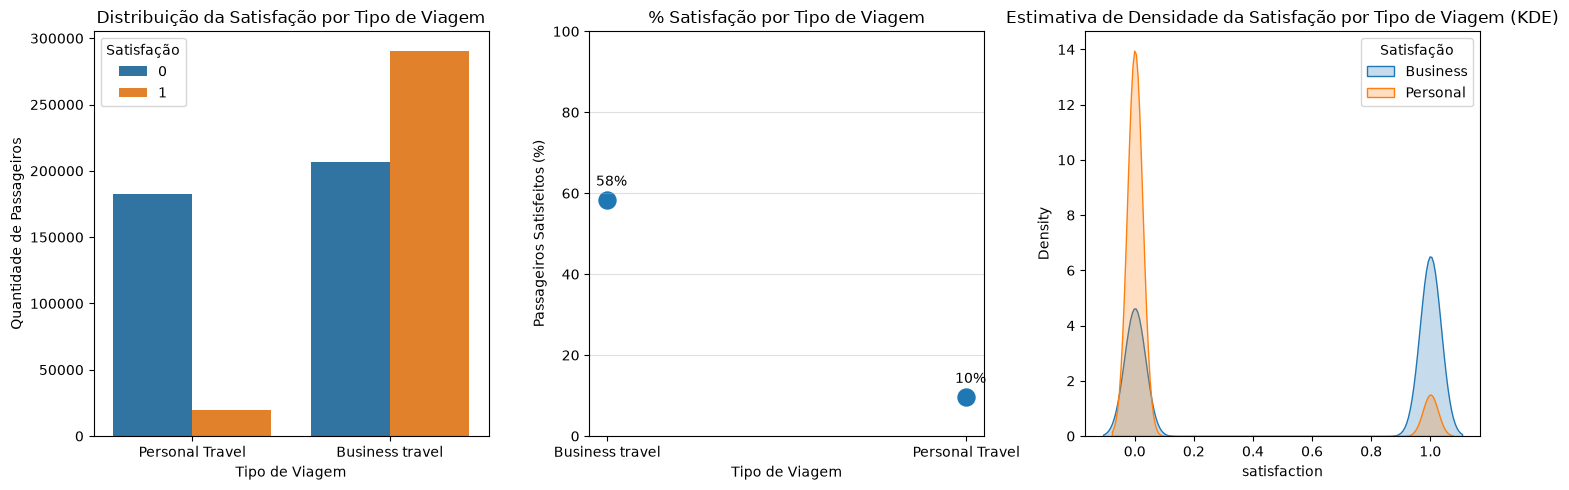

In [49]:
plt.figure(figsize=(15,5))

# Gráfico de Tipo de Viagem com Satisfação
plt.subplot( 1, 3 ,1)
sns.countplot(data=df2, x='type_of_travel',hue='satisfaction')
plt.title('Distribuição da Satisfação por Tipo de Viagem')
plt.xlabel('Tipo de Viagem')
plt.ylabel('Quantidade de Passageiros')
plt.legend(title='Satisfação')

# Gráfico de pontos Tipo de Viagem com Satisfação
plt.subplot( 1, 3 ,2)
# Calcular a taxa de satisfação por Tipo de Viagem
resultado = (df2.groupby('type_of_travel').apply(lambda x: (x['satisfaction'] == 1).mean()*100, include_groups=False).reset_index(name='satisfacao_percentual'))
# Criar o gráfico de dispersão com a taxa de satisfação por Tipo de Viagem
plt.scatter(resultado['type_of_travel'],resultado['satisfacao_percentual'],s=150)
# Mostrar o percentual acima de cada ponto
for _, row in resultado.iterrows():
    plt.annotate(f"{row['satisfacao_percentual']:.0f}%",(row['type_of_travel'], row['satisfacao_percentual']),xytext=(3, 10),textcoords='offset points',ha='center')

plt.title('% Satisfação por Tipo de Viagem')
plt.xlabel('Tipo de Viagem')
plt.ylabel('Passageiros Satisfeitos (%)')
plt.ylim(0, 100)
plt.grid(axis='y', alpha=0.4)

# Gráfico de Tipo de Viagem com Satisfação (KDE)
plt.subplot( 1, 3 ,3)
sns.kdeplot( df2[df2['type_of_travel'] == 'Business travel']['satisfaction'], label='Business', fill=True )
sns.kdeplot( df2[df2['type_of_travel'] == 'Personal Travel']['satisfaction'], label='Personal', fill=True )
plt.title('Estimativa de Densidade da Satisfação por Tipo de Viagem (KDE)')
plt.legend(title='Satisfação')

# Ajustar o layout
plt.tight_layout()

# Exibir os gráficos
plt.show()

### 3.2.1 Resumo das Hipóteses

In [50]:
tab =[['Hipóteses', 'Conclusão', 'Relevancia'],
['H1', 'Verdadeira', 'Alta'],
['H2', 'Verdadeira', 'Baixa'],
['H3', 'Falsa', 'Baixa'],
['H4', 'Verdadeira', 'Baixa'],
['H5', 'Verdadeira', 'Média'],
['H6', 'Verdadeira', 'Alta'],
['H7', 'Verdadeira', 'Média'],
['H8', 'Verdadeira', 'Alta'],
['H9', 'Verdadeira', 'Alta'],
['H10', 'Verdadeira', 'Baixa'],
['H11', 'Verdadeira', 'Alta']
]
print( tabulate( tab, headers='firstrow' ) )

Hipóteses    Conclusão    Relevancia
-----------  -----------  ------------
H1           Verdadeira   Alta
H2           Verdadeira   Baixa
H3           Falsa        Baixa
H4           Verdadeira   Baixa
H5           Verdadeira   Média
H6           Verdadeira   Alta
H7           Verdadeira   Média
H8           Verdadeira   Alta
H9           Verdadeira   Alta
H10          Verdadeira   Baixa
H11          Verdadeira   Alta


## 3.3 Análise Multivariada

### 3.3.1 Numerical Attributes 

In [51]:
# Atributos numéricos
num_attributes.head()

,age,flight_distance,inflight_wifi_service,departure_arrival_time_convenient,ease_of_online_booking,gate_location,food_and_drink,online_boarding,seat_comfort,inflight_entertainment,on_board_service,leg_room_service,baggage_handling,checkin_service,cleanliness,departure_delay_in_minutes,arrival_delay_in_minutes,satisfaction
0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,0
1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,1
2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,0
3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,0
4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,0


<Axes: >

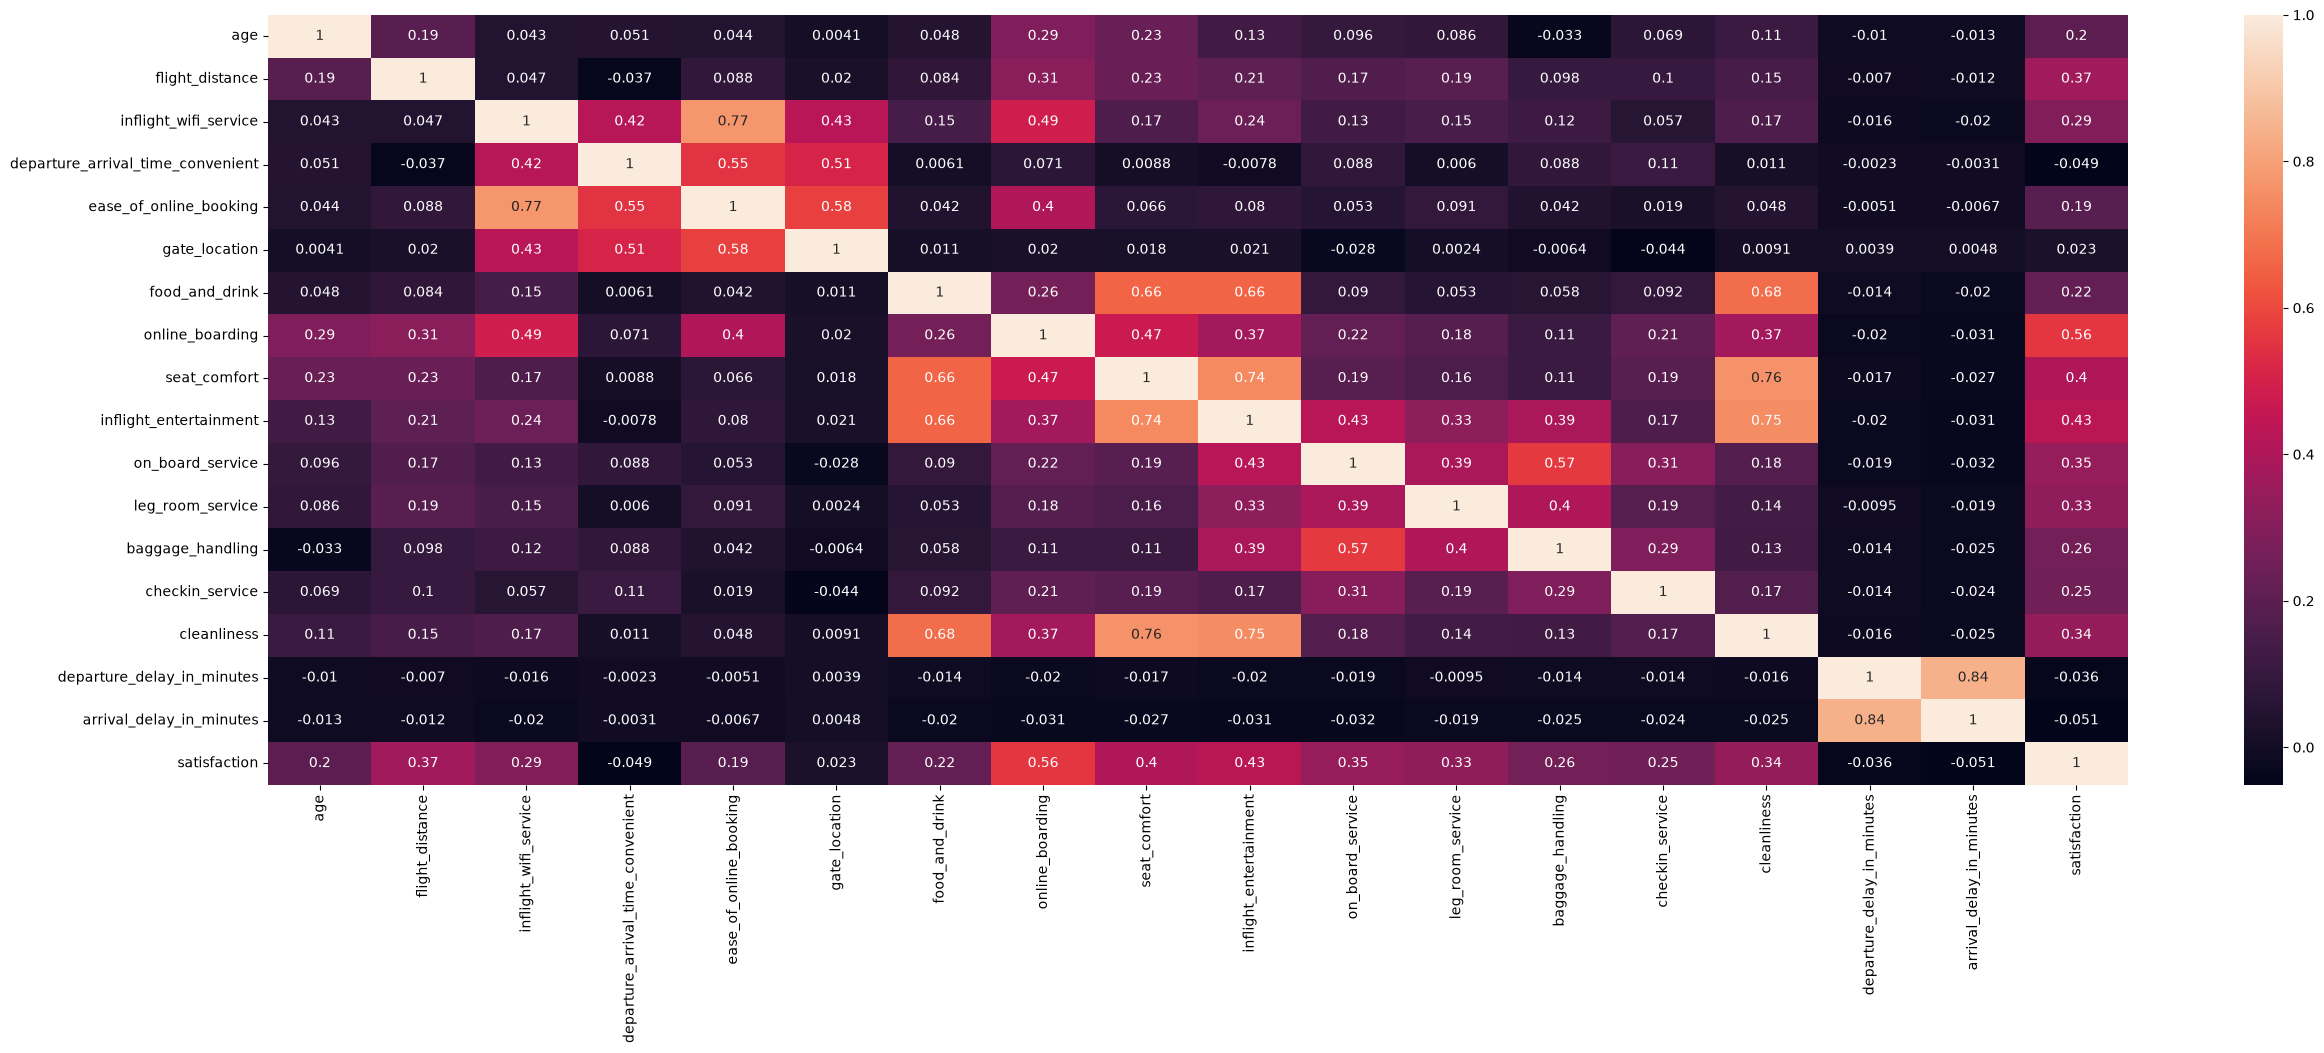

In [52]:
# Gráfico de Correlação
plt.figure(figsize=(30, 10))
correlation = num_attributes.corr(method='pearson')
sns.heatmap(correlation, annot=True)

### 3.3.2 Categorical Attributes

In [53]:
# Atributos categóricos
cat_attributes.head()

,gender,customer_type,type_of_travel,class
0,Female,Loyal Customer,Personal Travel,Eco
1,Male,Loyal Customer,Business travel,Business
2,Female,Loyal Customer,Personal Travel,Eco
3,Male,Loyal Customer,Personal Travel,Eco
4,Female,disloyal Customer,Business travel,Eco


In [54]:
# Criando um Dicionário Cramer V
def cramer_v (x,y):
    cm = pd.crosstab(x,y).to_numpy()
    n = cm.sum()
    r, k =cm.shape

    chi2 = ss.chi2_contingency(cm)[0]
    chi2corr = bt.max(0,chi2-(k-1)*(n-1)/(n-1))
    kcorr = k- (k-1)**2/(n-1)
    rcorr = r- (r-1)**2/(n-1)

    return np.sqrt((chi2corr/n)/(bt.min(kcorr-1, rcorr-1)))

In [55]:
# Cramer V (cm): Matriz de confusão: todas as combinações entre as variáveis categóricas
a1 = cramer_v(cat_attributes['class'], cat_attributes['class'])
a2 = cramer_v(cat_attributes['class'], cat_attributes['type_of_travel'])
a3 = cramer_v(cat_attributes['class'], cat_attributes['customer_type'])
a4 = cramer_v(cat_attributes['class'], cat_attributes['gender'])

a5 = cramer_v(cat_attributes['type_of_travel'], cat_attributes['class'])
a6 = cramer_v(cat_attributes['type_of_travel'], cat_attributes['type_of_travel'])
a7 = cramer_v(cat_attributes['type_of_travel'], cat_attributes['customer_type'])
a8 = cramer_v(cat_attributes['type_of_travel'], cat_attributes['gender'])

a9 = cramer_v(cat_attributes['customer_type'], cat_attributes['class'])
a10 = cramer_v(cat_attributes['customer_type'], cat_attributes['type_of_travel'])
a11 = cramer_v(cat_attributes['customer_type'], cat_attributes['customer_type'])
a12 = cramer_v(cat_attributes['customer_type'], cat_attributes['gender'])

a13 = cramer_v(cat_attributes['gender'], cat_attributes['class'])
a14 = cramer_v(cat_attributes['gender'], cat_attributes['type_of_travel'])
a15 = cramer_v(cat_attributes['gender'], cat_attributes['customer_type'])
a16 = cramer_v(cat_attributes['gender'], cat_attributes['gender'])

# Dataset final
d = pd.DataFrame({
  'class': [a1,a2,a3,a4],
  'type_of_travel': [a5,a6,a7,a8],
  'customer_type': [a9,a10,a11,a12],
  'gender': [a13,a14,a15,a16]})

d = d.set_index(d.columns)
d

,class,type_of_travel,customer_type,gender
class,1.000001,0.602674,0.143182,0.009528
type_of_travel,0.602675,0.999997,0.293060,0.024234
customer_type,0.143187,0.293060,0.999995,0.055909
gender,0.009603,0.024234,0.055909,0.999997


<Axes: >

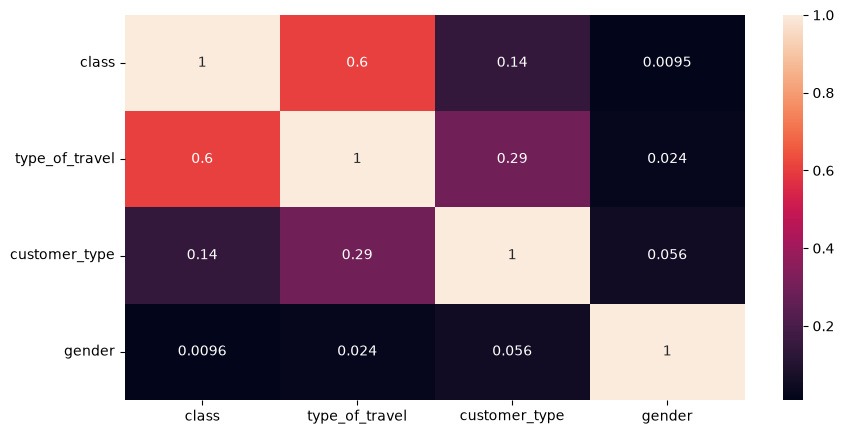

In [56]:
# Gráfico Cramer V (cm)
plt.figure(figsize=(10, 5))
sns.heatmap(d, annot=True)

# 4.0 Data Preparation 

## 4.1. Separação entre Treinamento e validação

In [57]:
df3 = df2.copy()

In [58]:
#ESSE PROCESSO JÁ DESENVOLVI ANTES
# # Convert response variable from categorial to numerical
# df3['Attrition'] = df5["Attrition"].apply(lambda x: 1 if x == "Yes" else 0)

X = df3.drop('satisfaction', axis=1)
y = df3['satisfaction']

# Train and Validation Split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

## 4.2. Padronização - teste de normalidade

### Teste de normalidade shapiro-Wilk e kosmogorov-Smirnov

In [59]:
num_cols = X_train.select_dtypes( include=['int64', 'float64'] ).columns.tolist()
cat_cols = X_train.select_dtypes( include=['str'] ).columns.tolist()

results_norm = []
for col in num_cols:
    series = X_train[col].dropna()

    # Shapiro-Wilk
    _, sw_p = stats.shapiro( series )

    # Kolmogorov-Smirnov vs normal padronizada
    z = ( series - series.mean() ) / series.std( ddof=0 )
    _, ks_p = stats.kstest( z, 'norm' )

    results_norm.append({
        'Feature': col,
        'Shapiro_p': sw_p,
        'KS_p': ks_p,
        'Normal_alpha_0.05': 'Yes' if (sw_p > 0.05) and (ks_p > 0.05) else 'No'
    })

df_normality = pd.DataFrame( results_norm ).sort_values( by='Shapiro_p', ascending=False )

df_normality.style.format({
    'Shapiro_p': '{:.4f}',
    'KS_p': '{:.4f}'
}).background_gradient( subset=['Shapiro_p', 'KS_p'], cmap='RdYlGn' )

/home/alvaro/.pyenv/versions/airline/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 559708.
  res = hypotest_fun_out(*samples, **kwds)


,Feature,Shapiro_p,KS_p,Normal_alpha_0.05
1,age,0.0000,0.0000,No
0,id,0.0000,0.0000,No
3,inflight_wifi_service,0.0000,0.0000,No
5,ease_of_online_booking,0.0000,0.0000,No
6,gate_location,0.0000,0.0000,No
8,online_boarding,0.0000,0.0000,No
4,departure_arrival_time_convenient,0.0000,0.0000,No
7,food_and_drink,0.0000,0.0000,No
15,cleanliness,0.0000,0.0000,No
14,checkin_service,0.0000,0.0000,No


### Rescaling

- Standad Scaler - Distribuição Normal, sem outliers
- Minmax Scaler - Distribuição não normal, sem outliers
- Robust Scaler - Distribuição não normal, com ou sem outliers

In [60]:
# Rescaling
robust_cols = ['age', 'flight_distance', 'inflight_wifi_service',
               'departure_arrival_time_convenient', 'ease_of_online_booking', 'gate_location',
               'food_and_drink', 'online_boarding', 'seat_comfort',
               'inflight_entertainment', 'on_board_service', 'leg_room_service', 
               'baggage_handling', 'checkin_service', 'cleanliness', 
               ]

#Min_max apenas em 'departure_delay_in_minutes', 'arrival_delay_in_minutes' porque essas duas variáveis não são normalmente distribuídas e o MinMaxScaler é mais robusto para variáveis não normalmente distribuídas.
min_max_cols = ['departure_delay_in_minutes', 'arrival_delay_in_minutes']

rs = pp.RobustScaler()
X_train[robust_cols] = rs.fit_transform(X_train[robust_cols])
X_val[robust_cols] = rs.transform(X_val[robust_cols])

mms = pp.MinMaxScaler()
X_train[min_max_cols] = mms.fit_transform(X_train[min_max_cols])
X_val[min_max_cols] = mms.transform(X_val[min_max_cols])

In [61]:
q = X_train[robust_cols].quantile([0.25, 0.5, 0.75]).T
q['IQR'] = q[0.75] - q[0.25]
print(q)

                                       0.25  0.5      0.75  IQR
age                               -0.565217  0.0  0.434783  1.0
flight_distance                   -0.273035  0.0  0.726965  1.0
inflight_wifi_service             -0.500000  0.0  0.500000  1.0
departure_arrival_time_convenient -0.500000  0.0  0.500000  1.0
ease_of_online_booking            -0.500000  0.0  0.500000  1.0
gate_location                     -0.500000  0.0  0.500000  1.0
food_and_drink                    -0.500000  0.0  0.500000  1.0
online_boarding                   -1.000000  0.0  0.000000  1.0
seat_comfort                      -0.500000  0.0  0.500000  1.0
inflight_entertainment            -0.666667  0.0  0.333333  1.0
on_board_service                  -1.000000  0.0  0.000000  1.0
leg_room_service                  -0.666667  0.0  0.333333  1.0
baggage_handling                  -0.500000  0.0  0.500000  1.0
checkin_service                   -1.000000  0.0  0.000000  1.0
cleanliness                       -1.000

## 4.3. Encoder

In [62]:
# ============================================================
# ENCODING DAS VARIÁVEIS CATEGÓRICAS
# Regra de ouro: aprender (fit) SÓ no treino; no validação/teste só aplicar (transform)
# ============================================================

# --- 1) Definição das colunas por tipo de encoder -----------
one_hot_cols = ['gender', 'customer_type', 'type_of_travel']  # categorias SEM ordem natural
ordinal_cols = ['class']                                       # categoria COM ordem (Eco < Eco Plus < Business)

# --- 2) Criação dos encoders (ainda não aprenderam nada) ----
ohe = pp.OneHotEncoder(
    sparse_output=False,     # devolve array comum (numpy) em vez de matriz esparsa
    handle_unknown='ignore', # se aparecer categoria nova no val/teste, preenche com 0 em vez de dar erro
    drop='if_binary'         # em colunas com 2 categorias, gera só 1 coluna (evita redundância)
)

oc = pp.OrdinalEncoder(
    categories=[['Eco', 'Eco Plus', 'Business']],  # ordem explícita: Eco=0, Eco Plus=1, Business=2
    dtype=int                                      # saída em inteiro (senão viria float)
)

# --- 3) Cópias para não alterar os DataFrames originais -----
# Evita o SettingWithCopyWarning e deixa a célula mais segura
X_train = X_train.copy()
X_val   = X_val.copy()

# --- 4) Ordinal Encoding (coluna 'class') -------------------
# fit_transform no treino: aprende o mapeamento E aplica
X_train[ordinal_cols] = oc.fit_transform(X_train[ordinal_cols])
# transform na validação: só aplica o mapeamento aprendido no treino (NUNCA fit aqui)
X_val[ordinal_cols]   = oc.transform(X_val[ordinal_cols])

# --- 5) One-Hot Encoding ------------------------------------
# fit: aprende quais categorias existem em cada coluna (usa só o treino)
ohe.fit(X_train[one_hot_cols])

# nomes das novas colunas, ex.: 'gender_Male', 'customer_type_disloyal Customer'
ohe_cols_out = ohe.get_feature_names_out(one_hot_cols)

# transform: converte as categorias em colunas 0/1 e já embrulha num DataFrame
# (index=... mantém o mesmo índice das linhas originais, essencial para o concat funcionar)
X_train_ohe = pd.DataFrame(ohe.transform(X_train[one_hot_cols]), columns=ohe_cols_out, index=X_train.index)
X_val_ohe   = pd.DataFrame(ohe.transform(X_val[one_hot_cols]),   columns=ohe_cols_out, index=X_val.index)

# --- 6) Junção final ----------------------------------------
# Remove as colunas de texto originais e cola as novas colunas 0/1 ao lado (axis=1 = colunas)
X_train = pd.concat([X_train.drop(columns=one_hot_cols), X_train_ohe], axis=1)
X_val   = pd.concat([X_val.drop(columns=one_hot_cols),   X_val_ohe],   axis=1)

# --- 7) Verificações ----------------------------------------
print(X_train.dtypes)                                        # nenhuma coluna deve ficar como texto
print(X_train.columns.tolist() == X_val.columns.tolist())    # True = treino e val têm as mesmas colunas, na mesma ordem
print(X_train.isna().sum().sum(), X_val.isna().sum().sum())  # 0 e 0 = nenhum NaN criado pelo encoding

id                                      int64
age                                   float64
flight_distance                       float64
inflight_wifi_service                 float64
departure_arrival_time_convenient     float64
ease_of_online_booking                float64
gate_location                         float64
food_and_drink                        float64
online_boarding                       float64
seat_comfort                          float64
inflight_entertainment                float64
on_board_service                      float64
leg_room_service                      float64
baggage_handling                      float64
checkin_service                       float64
cleanliness                           float64
departure_delay_in_minutes            float64
arrival_delay_in_minutes              float64
class                                   int64
faixa_atraso_partida                 category
faixa_atraso_chegada                 category
gender_Male                       

# 5.0. FEATURE SELECTION

In [63]:
df4 = df3.copy()

In [64]:
# SHAP (SHapley Additive exPlanations) é uma técnica de explicação de modelos de aprendizado de máquina que atribui a cada recurso a importância de sua contribuição para a previsão do modelo.
# Separar as variáveis explicativas (X) e a variável resposta (y)
df_shap = df4.copy()
X = df_shap.drop(columns=['satisfaction'])
y = df_shap['satisfaction']

# >>> PRECISA SER FEITO JÁ QUE A BASE É DE TREINO?
# Criar uma amostra estratificada (train_size=60000) para balancear a variável resposta
X_sample, _, y_sample, _ = train_test_split(
    X,
    y,
    train_size=60000,
    stratify=y,
    random_state=42
)

# Transformar variáveis categóricas em variáveis numéricas
X_encoded = pd.get_dummies(
    X_sample,
    drop_first=False,
    dtype=int
)

# Conferir o resultado
print('Dimensão de X:', X_encoded.shape)
print('Dimensão de y:', y_sample.shape)

print('\nDistribuição da variável resposta:')
print(y_sample.value_counts(normalize=True) * 100)

Dimensão de X: (60000, 37)
Dimensão de y: (60000,)

Distribuição da variável resposta:
satisfaction
0    55.643333
1    44.356667
Name: proportion, dtype: float64


In [65]:
#SHAP
# >>> PRECISA SER FEITO JÁ QUE A BASE É DE TREINO??
# Dividir os dados em treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y_sample,
    test_size=0.2,
    stratify=y_sample,
    random_state=42
)

# Criar o modelo
modelo = RandomForestClassifier(
    n_estimators=150,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Treinar o modelo
modelo.fit(X_train, y_train)

# Fazer previsões
y_pred = modelo.predict(X_test)

# Avaliar o modelo
print(classification_report(y_test, y_pred))

print('ROC AUC:', roc_auc_score(
    y_test,
    modelo.predict_proba(X_test)[:, 1]
))

              precision    recall  f1-score   support

           0       0.92      0.93      0.92      6677
           1       0.91      0.90      0.90      5323

    accuracy                           0.92     12000
   macro avg       0.92      0.91      0.91     12000
weighted avg       0.92      0.92      0.92     12000

ROC AUC: 0.9513590680640761


In [66]:
# Selecionar uma amostra para explicar
X_shap = X_test.sample(
    n=min(1000, len(X_test)),
    random_state=42
)

# Criar o explicador SHAP
explainer = shap.TreeExplainer(modelo)

# Calcular os valores SHAP
shap_values = explainer.shap_values(X_shap)

# Selecionar a classe de passageiros satisfeitos (True)
if isinstance(shap_values, list):
    shap_satisfaction = shap_values[1]
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    shap_satisfaction = shap_values[:, :, 1]
else:
    shap_satisfaction = shap_values

print('Dimensão dos valores SHAP:', shap_satisfaction.shape)

Dimensão dos valores SHAP: (1000, 37)


In [67]:
# Calcular a importância global
importancia_shap = pd.DataFrame({
    'Variavel': X_shap.columns,
    'Importancia_SHAP': np.abs(shap_satisfaction).mean(axis=0)
})

# Ordenar da maior para a menor importância
importancia_shap = importancia_shap.sort_values(
    by='Importancia_SHAP',
    ascending=False
)

# Exibir as 20 variáveis mais importantes
display(importancia_shap.head(20))

,Variavel,Importancia_SHAP
8,online_boarding,0.089148
3,inflight_wifi_service,0.058853
24,class_Business,0.054380
22,type_of_travel_Business travel,0.053455
23,type_of_travel_Personal Travel,0.049140
10,inflight_entertainment,0.042653
25,class_Eco,0.039178
9,seat_comfort,0.029068
21,customer_type_disloyal Customer,0.025483
11,on_board_service,0.023963


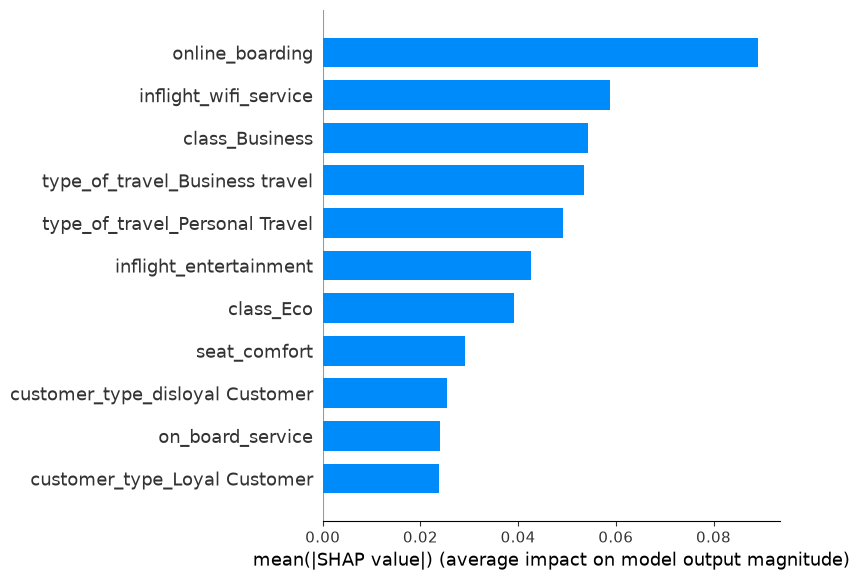

In [68]:
# Visualizar os TOP 10 valores SHAP
shap.summary_plot(
    shap_satisfaction,
    X_shap,
    plot_type='bar',
    max_display=11
)


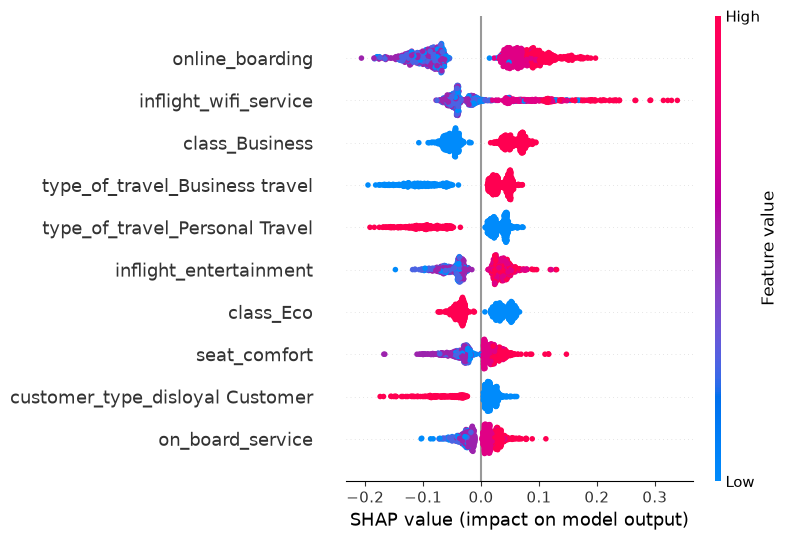

In [69]:
shap.summary_plot(
    shap_satisfaction,
    X_shap,
    max_display=10
)

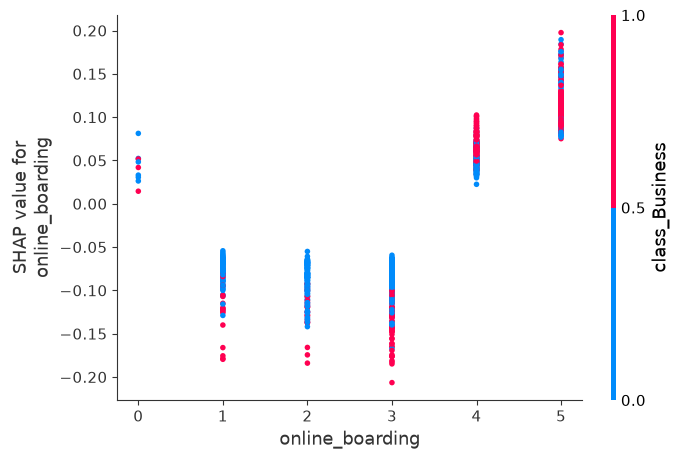

In [70]:
# Analisar a relação entre a variável 'online_boarding' e os valores SHAP para a classe de passageiros satisfeitos
shap.dependence_plot(
    'online_boarding',
    shap_satisfaction,
    X_shap
)

## 5.1. Filter Method

In [71]:
df5 = df4.copy()

In [72]:
# Remove variáveis com variância abaixo do threshold
selector = VarianceThreshold(threshold=0.01)
X_filtered = selector.fit_transform(num_attributes)

# Verificar variância manualmente
variances = num_attributes.var()
low_var_cols = variances[variances < 0.01].index.tolist()
print("Variáveis com variância quasi-zero:", low_var_cols)

Variáveis com variância quasi-zero: []


In [73]:
#ESSE TRECHO DO CÓDIGO SÓ DÁ PARA FINALIZAR APÓS A EDA QUE VAI AJUDAR NA DETERMINAÇÃO DE VARIÁVEIS DESCARTÁVEIS

# low_variance = []# EmployeeCount e StandardHours já removidas na célula 24 (variância zero)
# low_univariate_discriminative = []
# low_correlation = []

# low_bivariate_discriminative = []
# low_bivariate_cat_discriminative = []

# auto_corr = []

## 5.2 Wrapper Method Boruta

In [74]:
df5.sample(5)

,id,age,flight_distance,inflight_wifi_service,departure_arrival_time_convenient,ease_of_online_booking,gate_location,food_and_drink,online_boarding,seat_comfort,inflight_entertainment,on_board_service,leg_room_service,baggage_handling,checkin_service,cleanliness,departure_delay_in_minutes,arrival_delay_in_minutes,gender,customer_type,type_of_travel,class,satisfaction,faixa_atraso_partida,faixa_atraso_chegada
110799,110799,48,641,2,2,2,2,3,5,4,2,3,3,3,4,5,3,0.0,Male,Loyal Customer,Business travel,Business,1,1–15 min,Sem atraso
114200,114200,16,1426,3,1,3,2,4,3,4,4,2,2,2,2,4,0,0.0,Male,Loyal Customer,Personal Travel,Eco,0,Sem atraso,Sem atraso
595727,595727,41,1590,2,4,4,4,2,3,3,2,2,2,2,3,3,0,0.0,Male,Loyal Customer,Business travel,Business,0,Sem atraso,Sem atraso
409539,409539,67,646,4,5,4,4,4,4,4,4,3,2,3,1,4,0,0.0,Male,Loyal Customer,Business travel,Eco,0,Sem atraso,Sem atraso
455397,455397,24,641,1,5,1,1,2,1,2,2,3,1,4,3,2,0,0.0,Female,disloyal Customer,Business travel,Eco,0,Sem atraso,Sem atraso


In [75]:
#ENVIAR PARA HELPER FUNCTIONS
# Função para o boruta--- Reverter dummies para nome original
def to_original( col ):
    return col.split( '__SEP__' )[0] if '__SEP__' in col else col


# # preparacao dados
# X = df4.drop( columns='satisfaction' )
# y = df4['satisfaction'].apply(lambda x: 1 if x == 'Yes' else 0)

# X_boruta = pd.get_dummies( X, prefix_sep='__SEP__', dtype=int)

# # algoritmo
# rf = en.RandomForestClassifier(n_jobs=-1, max_depth=5, random_state=42)

# # boruta
# boruta = BorutaPy( rf, 
#                    n_estimators='auto',
#                    verbose=2,
#                    random_state=42
# ).fit( X_boruta.values, y.values )

# # resultados
# confirmed_boruta = X_boruta.columns[boruta.support_].tolist()
# tentative_boruta = X_boruta.columns[boruta.support_weak_].tolist()
# rejected_boruta = X_boruta.columns[~boruta.support_ & ~boruta.support_weak_].tolist()

# confirmed_boruta = sorted( set( to_original( c ) for c in confirmed_boruta ) )
# tentative_boruta = sorted( set( to_original( c ) for c in tentative_boruta ) )
# rejected_boruta  = sorted( set( to_original( c ) for c in rejected_boruta ) )

# # Categórica só é "rejeitada" se TODAS as suas dummies foram rejeitadas.
# # Se ao menos uma dummy foi confirmada/tentativa, removemos a original da lista de rejeitadas.
# rejected_boruta = [ c for c in rejected_boruta
#                       if c not in confirmed_boruta and c not in tentative_boruta ]

# print( f'Variaveis confirmadas (originais): {confirmed_boruta}' )
# print( f'Variaveis tentativas (originais):  {tentative_boruta}' )
# print( f'Variaveis rejeitadas (originais):  {rejected_boruta}' )

# #FINALIZAR QUANDO FINALIZAR A EDA
# # # --- 1) Filter Method
# # rejected_columns = ( low_variance 
# #                     + low_univariate_discriminative 
# #                     + low_correlation 
# #                     + low_bivariate_discriminative 
# #                     + low_bivariate_cat_discriminative 
# #                     + auto_corr
# #                     + rejected_boruta )

In [76]:
#rejected_columns = sorted( set(rejected_columns)) #ajuste pegando apenas as variáveis rejeitadas pelo Boruta
rejected_boruta = df5[['id']] # Salvei aqui para não precisar rodar o boruta todas vez

rejected_columns = sorted( set(rejected_boruta))

print( f"\nTotal de variáveis a serem removidas: {len(rejected_columns)}")
print( f"Variáveis a serem removidas: {rejected_columns}")


Total de variáveis a serem removidas: 1
Variáveis a serem removidas: ['id']


## 5.3 Wrapper Method RFECV

In [77]:
#NÃO CHEGUEI A USAR ESSE MÉTODO, MAS PODE SER ÚTIL PARA TESTAR SE O BORUTA ESTÁ FUNCIONANDO CORRETAMENTE.

# # Preparação simplificada para o Boruta (Encoding Temporário)
# X = df4.drop(columns=['satisfaction'])
# y = df4['satisfaction']#.apply(lambda x: 1 if x == 'Yes' else 0) Não precisa desse trecho porque eu já transformei a variável 'satisfaction' em 0 e 1 na célula 24

# X_rfe = pd.get_dummies(X)

# # RFE com número fixo de features
# rf = RandomForestClassifier(n_estimators=300, random_state=42)
# rfe = RFE(estimator=rf, n_features_to_select=10, step=1)
# rfe.fit(X_rfe, y)

# features_selecionadas = X_rfe.columns[rfe.support_].tolist()
# print("Features selecionadas pelo RFE:", features_selecionadas)

# # RFECV: encontra automaticamente o número ótimo via cross-validation
# rfecv = RFECV(
#     estimator=rf,
#     step=1,
#     cv=5,
#     scoring='roc_auc',
#     min_features_to_select=5
# )
# rfecv.fit(X_rfe, y)

# print(f"Número ótimo de features: {rfecv.n_features_}")
# print("Features:", X_rfe.columns[rfecv.support_].tolist())

## 5.4. Final Features Selection

In [78]:

df6 = df5.drop( columns=rejected_columns)
df6.shape

(699635, 24)

# 6.0. Machine Learning Modeling

## 6.1. Baseline Model

In [79]:
#Modelo de predição meramente aleatório, para servir de baseline para comparação com os modelos que serão criados posteriormente.
yhat_baseline_train = np.random.choice([0.1, 0.9], size = len(y_train), p=[0.5, 0.5])
yhat_baseline_val = np.random.choice([0.1, 0.9], size = len(y_val), p=[0.5, 0.5])

baseline_train = ml_metrics('Baseline Train', y_train, yhat_baseline_train )
baseline_val = ml_metrics('Baseline Val', y_val, yhat_baseline_val)

baseline = pd.concat( [baseline_train, baseline_val] )
baseline

,Model,Accuracy,F1 Score,precision,Recall,AUC
0,Baseline Train,0.497021,0.468719,0.440957,0.500211,0.497344
0,Baseline Val,0.501619,0.471469,0.445125,0.501128,0.501569


## 6.2 Regressão Logística

In [80]:
# definição
lr_model = LogisticRegression(random_state=42, max_iter=1000)

# treinamento
lr_model.fit(X_train, y_train)

# previsão
yhat_lr_train = lr_model.predict_proba(X_train)[:, 1]
yhat_lr_val = lr_model.predict_proba(X_val)[:, 1]

# desempenho
lr_train = ml_metrics('Logistic Regression Train', y_train, yhat_lr_train)
lr_val = ml_metrics('Logistic Regression Validation', y_val, yhat_lr_val)

lr = pd.concat([lr_train, lr_val])
lr

/home/alvaro/.pyenv/versions/airline/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


ValueError: The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- class
- faixa_atraso_chegada
- faixa_atraso_partida
Feature names seen at fit time, yet now missing:
- class_Business
- class_Eco
- class_Eco Plus
- customer_type_Loyal Customer
- faixa_atraso_chegada_16–30 min
- ...


## 6.3. Random Forest

In [ ]:
# definition
rf_model = en.RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    max_depth=5,
    random_state=42,
    n_jobs=-1
    )

# treinamento
rf_model.fit(X_train, y_train)

# previsão
yhat_rf_train = rf_model.predict_proba(X_train)[:, 1]
yhat_rf_val = rf_model.predict_proba(X_val)[:, 1]

# performance
rf_train = ml_metrics('Random Forest Train', y_train, yhat_rf_train)
rf_val = ml_metrics('Random Forest Validation', y_val, yhat_rf_val)

rf = pd.concat([rf_train, rf_val])
rf

,Model,Accuracy,F1 Score,precision,Recall,AUC
0,Random Forest Train,0.903900,0.892482,0.885880,0.899183,0.903422
0,Random Forest Validation,0.902907,0.891305,0.885243,0.897451,0.902353


## 6.4. LGBM Classifier

In [ ]:
# definition
lgbm_model = lgb.LGBMClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
# training
lgbm_model.fit(X_train, y_train)

# previsão
yhat_lgbm_train = lgbm_model.predict_proba(X_train)[:, 1]
yhat_lgbm_val = lgbm_model.predict_proba(X_val)[:, 1]

# performance
lgbm_train = ml_metrics('LightGBM Train', y_train, yhat_lgbm_train)
lgbm_val = ml_metrics('LightGBM Validation', y_val, yhat_lgbm_val)

lgbm = pd.concat([lgbm_train, lgbm_val])
lgbm

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 248271, number of negative: 311437
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.012304 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 590
[LightGBM] [Info] Number of data points in the train set: 559708, number of used features: 21
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000


,Model,Accuracy,F1 Score,precision,Recall,AUC
0,LightGBM Train,0.925366,0.915531,0.919255,0.911838,0.923995
0,LightGBM Validation,0.923289,0.913037,0.918275,0.907859,0.921724


## 6.5. XGBoost

In [ ]:
# definition
ratio = float( np.sum( y==0 ) ) / np.sum( y == 1 )
xgb_model = XGBClassifier(
    n_estimators = 100,
    scale_pos_weight = ratio,
    random_state=42,
    n_jobs=-1    
)

# training
xgb_model.fit(X_train, y_train)

# prediction
yhat_xgb_train = xgb_model.predict_proba(X_train)[:, 1]
yhat_xgb_val = xgb_model.predict_proba(X_val)[:, 1]

# performance
xgb_train = ml_metrics('XGBoost Train', y_train, yhat_xgb_train)
xgb_val = ml_metrics('XGBoost Validation', y_val, yhat_xgb_val)

xgb = pd.concat([xgb_train, xgb_val])
xgb

,Model,Accuracy,F1 Score,precision,Recall,AUC
0,XGBoost Train,0.927496,0.917985,0.921230,0.914762,0.926205
0,XGBoost Validation,0.923646,0.913509,0.918028,0.909035,0.922164


In [ ]:
print( "===== Training Metrics ====")
display( pd.concat( [baseline_train, lr_train, rf_train, lgbm_train, xgb_train] ).reset_index(drop=True))

print( "===== Validation Metrics ====")
display( pd.concat( [baseline_val, lr_val, rf_val, lgbm_val, xgb_val] ).reset_index(drop=True))

===== Training Metrics ====


,Model,Accuracy,F1 Score,precision,Recall,AUC
0,Baseline Train,0.499855,0.469608,0.443360,0.499160,0.499785
1,Logistic Regression Train,0.878392,0.860763,0.874537,0.847417,0.875251
2,Random Forest Train,0.903900,0.892482,0.885880,0.899183,0.903422
3,LightGBM Train,0.925366,0.915531,0.919255,0.911838,0.923995
4,XGBoost Train,0.927496,0.917985,0.921230,0.914762,0.926205


===== Validation Metrics ====


,Model,Accuracy,F1 Score,precision,Recall,AUC
0,Baseline Val,0.500404,0.468965,0.443665,0.497326,0.500092
1,Logistic Regression Validation,0.877801,0.859962,0.874523,0.845879,0.874563
2,Random Forest Validation,0.902907,0.891305,0.885243,0.897451,0.902353
3,LightGBM Validation,0.923289,0.913037,0.918275,0.907859,0.921724
4,XGBoost Validation,0.923646,0.913509,0.918028,0.909035,0.922164
